# HerbaNusa — Pipeline ML Lengkap (Tahap 0–6)

Notebook ini berisi seluruh proses dari data mentah sampai model `.tflite`
yang siap dipakai aplikasi: EDA data mentah, bersihkan data, latih tiga
algoritma, bandingkan, export ke TFLite, lalu tentukan kapan model boleh
menjawab. Semua sel sudah dijalankan, jadi grafik dan tabel di bawah ini
adalah hasil asli, bukan gambar tempelan.

Setiap sel yang mengeluarkan output langsung diikuti satu paragraf
**Penjelasan output** (log, tabel, atau grafik) supaya hasilnya bisa dibaca
tanpa menebak. Angka di dalam penjelasan selalu merujuk ke output tepat di
atasnya.

| | |
|---|---|
| Dataset | 10.000 gambar, 100 spesies, asli 128×128 |
| Model final | MobileNetV2 fine-tune, input 224×224, 2,39 juta parameter |
| Hasil test | top-1 **89,16%**, top-3 **95,26%** |
| Dengan `AMBANG = 0.27` | 93% foto dijawab, akurasi **92,7%** |
| Artefak | `model.tflite` **4,56 MB**, float16 |
| Waktu eksekusi | ± 80 menit, CPU 4 core, tanpa GPU |

Soal variasi angka: augmentasi gambar memakai RNG, jadi kalau dijalankan ulang
hasilnya bisa bergeser sedikit walaupun seed-nya sama. Run sebelumnya pernah
dapat top-1 85,03%. Angka di notebook ini yang dipakai di laporan.

## Isi

| Tahap | Kode | Waktu |
|---|---|---|
| 0 | `00_eda.py` — EDA pada data mentah | 1 mnt |
| 1 | `00_prepare.py` — bersihkan data + split | 2 mnt |
| 2 | `01_train_cnn.py` — model final 224px | 60 mnt |
| 3 | `02_svm.py` — model 2 | 1 mnt |
| 4 | `03_rf.py` — model 3 | 1 mnt |
| 5 | `04_compare.py` — perbandingan | 10 dtk |
| 6 | `05_export_tflite.py` — export + verifikasi | 12 mnt |
| 6a | `06_threshold.py` — ambang penolakan | 5 dtk |
| 6b | `06b_svm_deploy.py` — biaya deploy SVM | 2 mnt |

## Catatan

- Semua path absolut ke folder `tanaman-obat`. Kalau folder dipindah, ubah di
  sel pertama tiap tahap.
- Menjalankan ulang notebook ini menimpa folder `output/`. Angka bisa bergeser
  sedikit karena augmentasi acak.
- Tanpa GPU. Pastikan laptop tidak sleep saat training.
- Percobaan 128px dan TTA tidak dimasukkan karena tidak dipakai di model final.


---

# Tahap 0 · EDA (Exploratory Data Analysis)

Analisis awal pada data **mentah** sebelum dibersihkan dan sebelum
preprocessing citra.

**Tujuan:** mengetahui ukuran, resolusi, kebersihan data (duplikat/missing),
sebaran sampel per kelas, dan karakter piksel (brightness, kontras) supaya
keputusan pembersihan dan preprocessing tepat.

> **Catatan urutan.** EDA di sini sengaja dijalankan **sebelum** Tahap 1.
> Pembersihan duplikat dan split ada di Tahap 1, sedangkan preprocessing citra
> (resize 224, augmentasi, normalisasi) baru ada di Tahap 2.

### 0.1 Informasi Dataset

Membaca folder mentah dan menghitung statistik tiap gambar: resolusi, mode warna, brightness, kontras, dan ukuran file.

In [1]:
import hashlib
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import OUT, show_fig, tampil  # noqa: E402

warnings.filterwarnings("ignore")

ROOT = Path(r"C:\Users\Wahyu Pratomo\Downloads\Indonesia-Medicinal-Plant-dataset\Indonesia-Medicinal-Plant-Dataset")
NEAR_DUP_MAX = 2

D = OUT / "eda"
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
# --- baca folder mentah + hitung statistik tiap gambar ---
paths, kelas, md5s, lebar, tinggi, mode, bright, kontras, kb, hashes = [], [], [], [], [], [], [], [], [], []
for _d in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    for _f in sorted(_d.iterdir()):
        if not (_f.is_file() and _f.suffix.lower() == ".jpg"):
            continue
        _raw = _f.read_bytes()
        with Image.open(_f) as im:
            _w, _h = im.size
            _mode = im.mode
            _gray = np.asarray(im.convert("L"), dtype=np.uint8)
            _small = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
        paths.append(str(_f)); kelas.append(_d.name)
        md5s.append(hashlib.md5(_raw).hexdigest())
        lebar.append(_w); tinggi.append(_h); mode.append(_mode)
        bright.append(float(_gray.mean())); kontras.append(float(_gray.std()))
        kb.append(len(_raw) / 1024)
        hashes.append((_small[:, 1:] > _small[:, :-1]).flatten())

df = pd.DataFrame({
    "path": paths, "label": kelas, "md5": md5s, "lebar": lebar, "tinggi": tinggi,
    "mode": mode, "brightness": bright, "contrast": kontras, "ukuran_kb": kb,
})
print(f"gambar mentah: {len(df):,} | kelas: {df.label.nunique()}", flush=True)

gambar mentah: 10,000 | kelas: 100


**Penjelasan output (log):** baris `gambar mentah: 10,000 | kelas: 100` adalah hasil penelusuran folder dataset. Ada 10.000 file JPG yang terbaca dan 100 folder spesies, jadi tidak ada file yang terlewat. Karena belum ada pembersihan, jumlah ini masih data mentah.

In [3]:
# --- cek duplikat (ditemukan di EDA, dibersihkan di tahap berikutnya) ---
mask = ~df.duplicated("md5").values
dup_persis = int((~mask).sum())
sisa = df[mask].reset_index(drop=True)
h = [hashes[k] for k in np.where(mask)[0]]
keep = np.ones(len(sisa), dtype=bool)
for _lab in sisa.label.unique():
    idxs = np.where(sisa.label.values == _lab)[0]
    kept = []
    for i in idxs:
        if any(int((h[i] != h[j]).sum()) <= NEAR_DUP_MAX for j in kept):
            keep[i] = False
        else:
            kept.append(i)
dup_mirip = int((~keep).sum())
print(f"duplikat persis: {dup_persis} | near-duplicate (setelah duplikat persis): {dup_mirip}", flush=True)

duplikat persis: 69 | near-duplicate (setelah duplikat persis): 92


**Penjelasan output (log):** `duplikat persis: 69` berarti 69 file punya isi byte yang sama persis (MD5 identik). `near-duplicate (setelah duplikat persis): 92` berarti setelah 69 file itu disingkirkan, masih ada 92 gambar yang mirip (jarak dHash ≤ 2). Total 161 gambar bermasalah. Angka ini hanya **ditemukan** di EDA; pembuangannya dilakukan di Tahap 1.

In [4]:
# --- tabel informasi dataset ---
tampil("Informasi dataset (mentah)", pd.DataFrame({
    "Item": ["Jumlah gambar", "Jumlah kelas", "Resolusi", "Mode warna",
             "Format file", "Ukuran file (rata-rata)", "Gambar per kelas"],
    "Nilai": [f"{len(df):,}", f"{df.label.nunique()}",
              f"{int(df.lebar.min())}x{int(df.tinggi.min())}",
              ", ".join(sorted(df['mode'].unique())), "JPG",
              f"{df.ukuran_kb.mean():.1f} KB (min {df.ukuran_kb.min():.1f}, maks {df.ukuran_kb.max():.1f})",
              f"{int(df.label.value_counts().min())}-{int(df.label.value_counts().max())}"],
}))

**Informasi dataset (mentah)**

,Item,Nilai
0,Jumlah gambar,"10,000"
1,Jumlah kelas,100
2,Resolusi,128x128
3,Mode warna,RGB
4,Format file,JPG
5,Ukuran file (rata-rata),"9.3 KB (min 3.6, maks 13.5)"
6,Gambar per kelas,100-100


**Penjelasan output (tabel):** tabel ringkasan bentuk dataset mentah. Semua 10.000 gambar berukuran 128×128 piksel, mode RGB, format JPG, dan ukuran file 3,6–13,5 KB (rata-rata 9,3 KB). Kolom `Gambar per kelas = 100-100` berarti setiap kelas punya tepat 100 gambar, jadi dataset mentah seimbang sempurna.

**Interpretasi.** Data mentah berisi 10.000 gambar, tepat 100 per kelas, semuanya 128×128 piksel dan RGB. Ukuran rata-rata 9,3 KB, jadi seluruh dataset masih ringan.

### 0.2 Pemeriksaan Missing Value dan Duplikat

Memastikan tidak ada sel kosong atau file hilang, lalu menghitung duplikat persis (MD5) dan near-duplicate (dHash) yang nanti dibuang di Tahap 1.

In [5]:
# --- cek missing dan duplikat ---
tampil("Pemeriksaan kualitas data", pd.DataFrame({
    "Pemeriksaan": ["Sel kosong", "File tidak ditemukan", "Duplikat persis (MD5)",
                    "Near-duplicate (dHash)"],
    "Hasil": [int(df[["path", "label"]].isna().sum().sum()),
              int(sum(not Path(p).exists() for p in df.path)), dup_persis, dup_mirip],
}))

**Pemeriksaan kualitas data**

,Pemeriksaan,Hasil
0,Sel kosong,0
1,File tidak ditemukan,0
2,Duplikat persis (MD5),69
3,Near-duplicate (dHash),92


**Penjelasan output (tabel):** hasil pemeriksaan kualitas data. `Sel kosong = 0` dan `File tidak ditemukan = 0` menandakan tidak ada data hilang. Dua baris terakhir mengulang temuan duplikat: 69 duplikat persis dan 92 near-duplicate. Karena masih di tahap EDA, duplikat ini **belum** dibuang.

**Interpretasi.** Tidak ada sel kosong atau file hilang. Namun ada 69 gambar identik dan 92 near-duplicate. Total 161 gambar bermasalah ini dibuang di Tahap 1, sehingga 10.000 turun jadi 9.839 sebelum split, supaya tidak ada gambar yang bocor ke test.

### 0.3 Distribusi Sebaran Kelas

Melihat apakah jumlah gambar tiap kelas seimbang sebelum data dibagi.

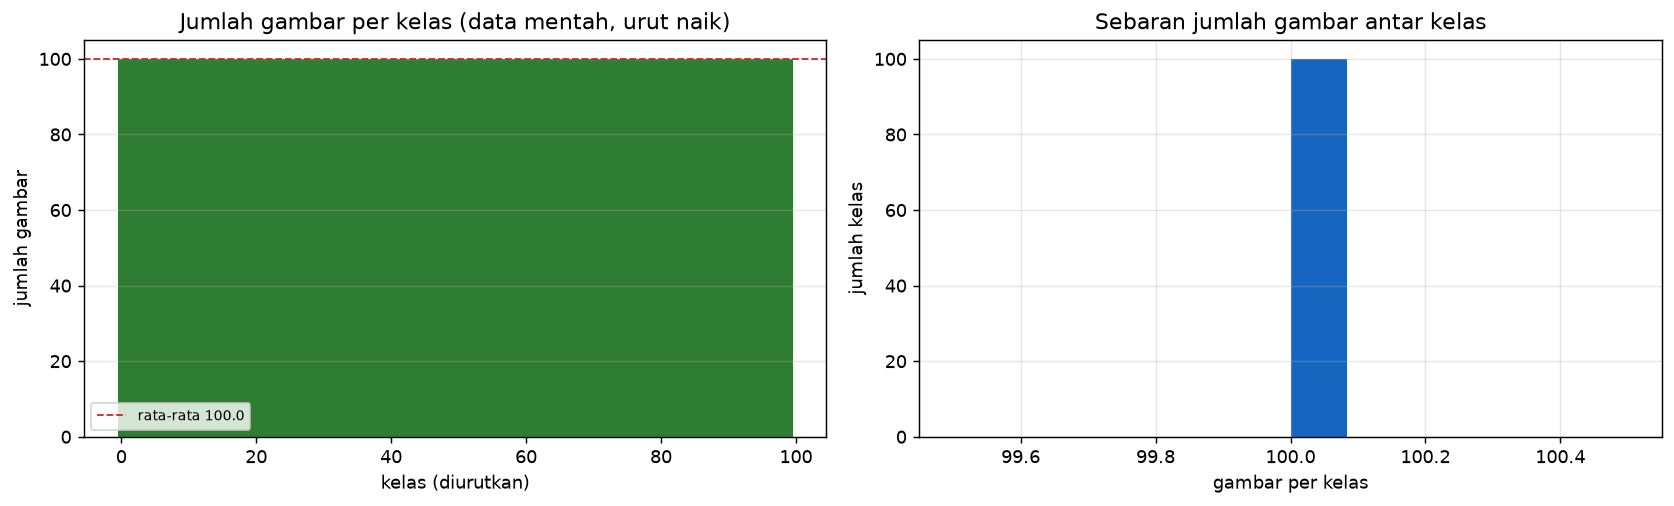

In [6]:
# --- grafik distribusi kelas ---
jumlah = df.label.value_counts().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(len(jumlah)), jumlah.values, color="#2e7d32", width=1.0)
ax[0].axhline(jumlah.mean(), color="#c62828", ls="--", lw=1,
              label=f"rata-rata {jumlah.mean():.1f}")
ax[0].set_title("Jumlah gambar per kelas (data mentah, urut naik)")
ax[0].set_xlabel("kelas (diurutkan)"); ax[0].set_ylabel("jumlah gambar")
ax[0].grid(axis="y", alpha=.3); ax[0].legend(fontsize=8)
ax[1].hist(jumlah.values, bins=12, color="#1565c0")
ax[1].set_title("Sebaran jumlah gambar antar kelas")
ax[1].set_xlabel("gambar per kelas"); ax[1].set_ylabel("jumlah kelas")
ax[1].grid(alpha=.3)
show_fig(fig, FIG / "distribusi_kelas.png", dpi=130)

**Penjelasan output (grafik):** dua grafik distribusi kelas pada data mentah. Grafik kiri menunjukkan setiap kelas berada di angka 100 (garis putus-putus merah = rata-rata 100,0), jadi batangnya rata sempurna. Grafik kanan menegaskan hal yang sama: seluruh 100 kelas jatuh di satu bin 100 gambar. Artinya tidak ada kelas yang kekurangan sampel di data mentah.

In [7]:
# --- tabel sebaran kelas ---
tampil("Sebaran jumlah gambar per kelas", pd.DataFrame({
    "Keterangan": ["Jumlah kelas", "Total gambar", "Min per kelas", "Maks per kelas",
                   "Rata-rata per kelas"],
    "Nilai": [f"{df.label.nunique()}", f"{len(df):,}", int(jumlah.min()), int(jumlah.max()),
              f"{jumlah.mean():.1f}"],
}))

**Sebaran jumlah gambar per kelas**

,Keterangan,Nilai
0,Jumlah kelas,100
1,Total gambar,"10,000"
2,Min per kelas,100
3,Maks per kelas,100
4,Rata-rata per kelas,100.0


**Penjelasan output (tabel):** tabel angka dari grafik sebelumnya. 100 kelas, total 10.000 gambar, minimum dan maksimum per kelas sama-sama 100, rata-rata 100,0. Dataset mentah benar-benar seimbang, sehingga teknik penyeimbangan kelas (oversampling, class weight) tidak diperlukan di tahap awal.

**Interpretasi.** Setiap kelas tepat 100 gambar, jadi dataset mentah sebenarnya seimbang. Setelah dibersihkan jumlahnya bergeser sedikit (56–70 per kelas di train), itu wajar karena duplikat tidak merata.

### 0.4 Karakteristik Fitur Citra

Distribusi brightness, kontras, dan ukuran file untuk melihat variasi visual antar foto.

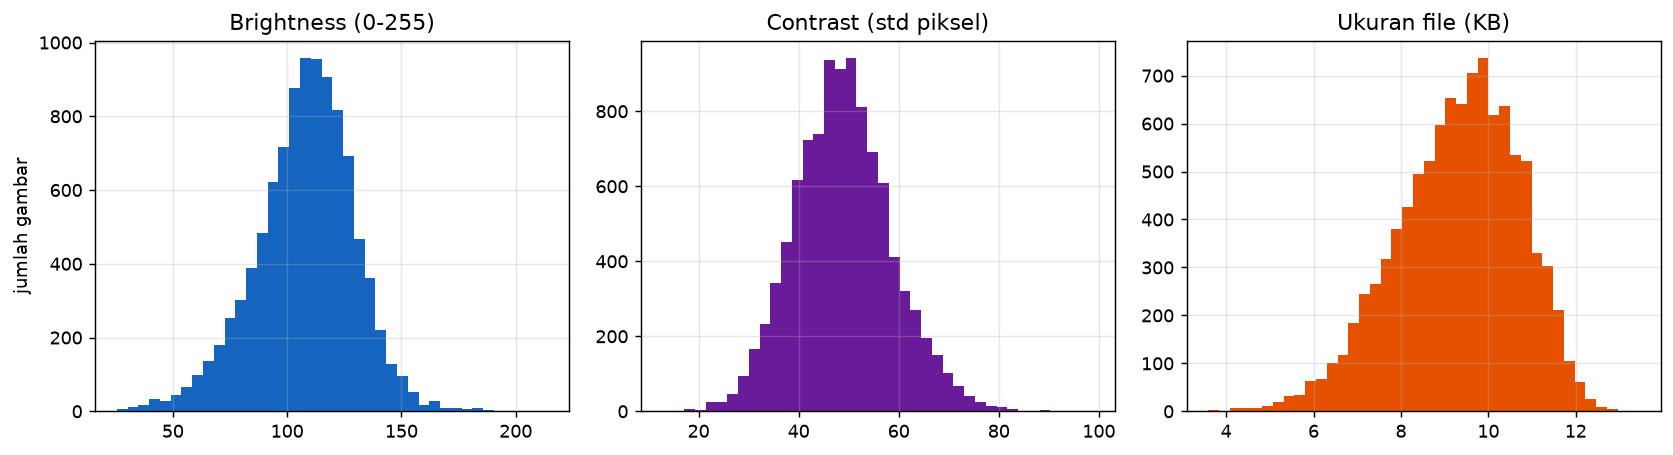

In [8]:
# --- grafik distribusi fitur gambar ---
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(df.brightness, bins=40, color="#1565c0")
ax[0].set_title("Brightness (0-255)"); ax[0].set_ylabel("jumlah gambar")
ax[1].hist(df.contrast, bins=40, color="#6a1b9a")
ax[1].set_title("Contrast (std piksel)")
ax[2].hist(df.ukuran_kb, bins=40, color="#e65100")
ax[2].set_title("Ukuran file (KB)")
for a in ax:
    a.grid(alpha=.3)
show_fig(fig, FIG / "distribusi_fitur.png", dpi=130)

**Penjelasan output (grafik):** tiga histogram fitur piksel. Brightness (kiri) menyebar lebar kira-kira 25–214 dengan puncak di sekitar 110, artinya foto diambil dalam kondisi cahaya yang bervariasi. Contrast (tengah) memusat di sekitar 48 dengan ekor ke kanan. Ukuran file (kanan) mengumpul di sekitar 9 KB dan tidak ada file yang ukurannya ekstrem.

In [9]:
# --- tabel statistik fitur ---
tampil("Statistik fitur gambar",
       df[["brightness", "contrast", "ukuran_kb"]].describe().round(2).T.reset_index()
       .rename(columns={"index": "Fitur"}))

**Statistik fitur gambar**

,Fitur,count,mean,std,min,25%,50%,75%,max
0,brightness,10000.0,107.80,21.69,25.48,95.03,109.18,122.21,214.04
1,contrast,10000.0,48.91,9.71,12.80,42.34,48.65,54.98,98.94
2,ukuran_kb,10000.0,9.31,1.40,3.59,8.38,9.43,10.34,13.45


**Penjelasan output (tabel):** statistik deskriptif ketiga fitur. Brightness rata-rata 107,80 dengan simpangan baku 21,69 dan rentang 25,48–214,04. Contrast rata-rata 48,91, rentang 12,80–98,94. Ukuran file rata-rata 9,31 KB, rentang 3,59–13,45 KB. Kolom `count = 10000` memastikan tidak ada nilai kosong yang diam-diam terlewat.

**Interpretasi.** Brightness berkisar 25–214 dengan rata-rata 108, sedangkan kontras 13–99. Foto diambil dalam kondisi cahaya beragam, jadi augmentasi kecerahan dan kontras nanti relevan.

### 0.5 Pemeriksaan Outlier

Mendeteksi foto yang terlalu gelap, terlalu terang, atau berukuran ekstrem dengan aturan 1,5 × IQR.

In [10]:
# --- outlier ---
def hitung_outlier(kolom):
    q1, q3 = kolom.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((kolom < lo) | (kolom > hi)).sum()), lo, hi
outlier = {k: hitung_outlier(df[k]) for k in ("brightness", "contrast", "ukuran_kb")}

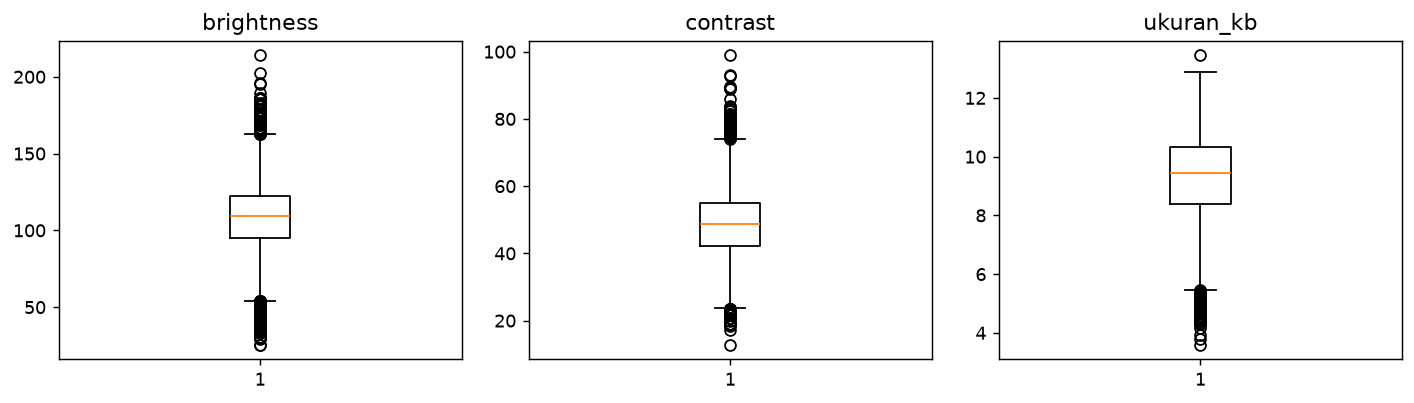

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, k in zip(ax, ("brightness", "contrast", "ukuran_kb")):
    a.boxplot(df[k])
    a.set_title(k)
show_fig(fig, FIG / "outlier.png", dpi=130)

**Penjelasan output (grafik):** tiga boxplot untuk deteksi outlier secara visual. Kotak adalah rentang 25–75 persen, garis tengah adalah median. Titik-titik di luar kumis adalah outlier. Terlihat outlier hanya sedikit dan tersebar tipis di kedua ujung, bukan kelompok besar yang mengindikasikan data rusak.

In [12]:
# --- tabel outlier ---
tampil("Pemeriksaan outlier (aturan 1.5 x IQR)", pd.DataFrame({
    "Fitur": list(outlier),
    "Jumlah outlier": [v[0] for v in outlier.values()],
    "Persen": [f"{100 * v[0] / len(df):.1f}%" for v in outlier.values()],
    "Batas bawah": [round(v[1], 1) for v in outlier.values()],
    "Batas atas": [round(v[2], 1) for v in outlier.values()],
}))

**Pemeriksaan outlier (aturan 1.5 x IQR)**

,Fitur,Jumlah outlier,Persen,Batas bawah,Batas atas
0,brightness,213,2.1%,54.3,163.0
1,contrast,124,1.2%,23.4,73.9
2,ukuran_kb,69,0.7%,5.4,13.3


**Penjelasan output (tabel):** jumlah outlier dengan aturan 1,5 × IQR. Brightness punya 213 outlier (2,1%), contrast 124 (1,2%), ukuran file 69 (0,7%). Kolom batas bawah/atas adalah pagar IQR; nilai di luarnya dihitung outlier. Semuanya di bawah 2,2%, jadi outlier dipertahankan karena masih berupa foto wajar (misalnya daun yang sangat terang).

**Interpretasi.** Outlier IQR hanya 0,7–2,1% dari data. Jumlahnya kecil dan gambarnya masih wajar (bukan rusak), jadi lebih baik dipertahankan supaya model terbiasa dengan kondisi nyata.

### 0.6 Korelasi Antar Fitur

Memeriksa hubungan antar fitur citra sebelum memutuskan apakah ada fitur yang perlu dibuang.

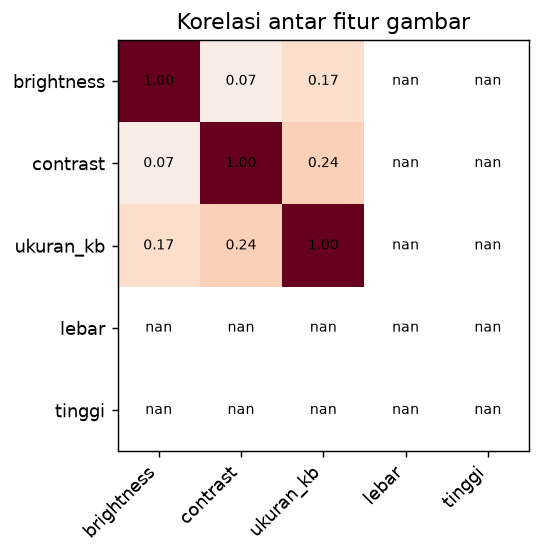

In [13]:
# --- korelasi ---
corr = df[["brightness", "contrast", "ukuran_kb", "lebar", "tinggi"]].corr()
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Korelasi antar fitur gambar")
show_fig(fig, FIG / "korelasi_fitur.png", dpi=130)

**Penjelasan output (grafik):** heatmap korelasi antar lima fitur. Angka mendekati +1 berarti naik bersama, mendekati -1 berarti berlawanan. Hampir semua sel bernilai kecil (di bawah 0,2), jadi antar fitur tidak ada hubungan kuat. Sel `lebar`–`tinggi` bernilai 1,00 karena semua gambar berukuran sama (128×128), bukan informasi baru.

**Interpretasi.** Korelasi antar fitur lemah dan lebar/tinggi gambar konstan di 128. Untuk klasifikasi citra, korelasi piksel memang tidak relevan, jadi tidak ada fitur yang perlu dibuang.

### 0.7 Contoh Gambar Tiap Kelas

Menampilkan 20 sampel acak dari kelas yang berbeda untuk melihat variasi visualnya.

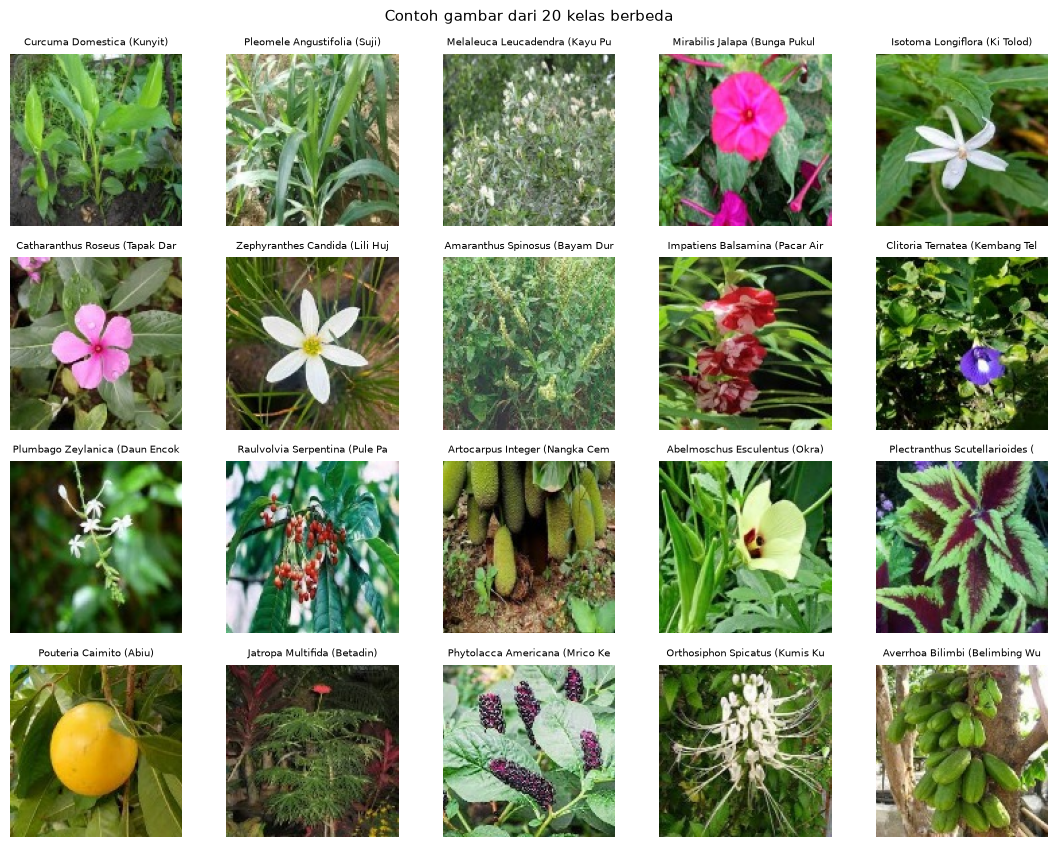

DONE EDA


In [14]:
# --- contoh gambar ---
rng = np.random.default_rng(7)
pilih = rng.choice(df.label.nunique(), 20, replace=False)
nama_kelas = sorted(df.label.unique())
fig, axes = plt.subplots(4, 5, figsize=(11, 8.6))
for a, k in zip(axes.ravel(), pilih):
    nama = nama_kelas[k]
    contoh = df[df.label == nama].sample(1, random_state=int(k) + 1).path.iloc[0]
    with Image.open(contoh) as im:
        a.imshow(im.convert("RGB"))
    a.set_title(nama[:30], fontsize=7)
    a.axis("off")
fig.suptitle("Contoh gambar dari 20 kelas berbeda", fontsize=11)
show_fig(fig, FIG / "contoh_gambar.png", dpi=100)

print("DONE EDA", flush=True)

**Penjelasan output (grafik + log):** grid 20 contoh gambar dari 20 kelas berbeda, satu gambar per kelas. Tujuannya melihat variasi visual nyata: latar, sudut pengambilan, dan pencahayaan berbeda-beda meskipun objeknya sama jenis. Baris `DONE EDA` hanya penanda bahwa seluruh sel EDA selesai dijalankan.

**Interpretasi.** Latar, sudut, dan pencahayaan setiap foto berbeda walaupun kelasnya sama. Ini alasan augmentasi dan fine-tuning dipakai, bukan menambah epoch saja.

---

# Tahap 1 · Persiapan Data (cleaning + split)

Membersihkan dataset mentah lalu membagi jadi train/val/test.

**Tujuan:** membuang gambar duplikat dan membagi data secara stratified supaya
tidak ada kebocoran antara train, val, dan test.

**Bukan preprocessing citra.** Di tahap ini belum ada resize, augmentasi, atau
normalisasi piksel. Itu semua baru dilakukan di Tahap 2.

**Masuk:** 10.000 gambar mentah, 100 folder spesies, 128×128.
**Keluar:** `output/_data/` (`labels.json`, `train.csv`, `val.csv`, `test.csv`,
`dataset_report.csv`).

Hasil: 10.000 → 9.839 gambar (6.887 / 1.476 / 1.476).

### 1.1 Menyiapkan Alat dan Library

Memuat library untuk pembersihan data (`hashlib` untuk MD5, `pandas`, `PIL`).

In [15]:
import hashlib
import json
import sys
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

ImageFile.LOAD_TRUNCATED_IMAGES = True

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import DATA, OUT  # noqa: E402

ROOT = Path(r"C:\Users\Wahyu Pratomo\Downloads\Indonesia-Medicinal-Plant-dataset\Indonesia-Medicinal-Plant-Dataset")
NEAR_DUP_MAX = 2

In [16]:
def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()


def dhash(p, size=8):
    with Image.open(p) as im:
        a = np.asarray(im.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

### 1.2 Membaca Dataset Mentah

Menelusuri folder spesies dan mengumpulkan daftar file gambar.

In [17]:
print("=== TAHAP 0-1: cek dataset + pembersihan ===", flush=True)
rows = []
for d in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    for f in sorted(d.iterdir()):
        if f.is_file() and f.suffix.lower() == ".jpg":
            rows.append({"path": str(f), "label": d.name})
df = pd.DataFrame(rows)
print(f"file terbaca: {len(df):,} | folder: {df.label.nunique()}", flush=True)

=== TAHAP 0-1: cek dataset + pembersihan ===


file terbaca: 10,000 | folder: 100


**Penjelasan output (log):** `=== TAHAP 0-1: cek dataset + pembersihan ===` adalah judul proses, lalu `file terbaca: 10,000 | folder: 100` mengonfirmasi tahap pembersihan membaca ulang seluruh 10.000 file dari 100 folder. Jumlahnya sama dengan EDA, jadi tidak ada file yang berubah atau hilang di antara kedua tahap.

### 1.3 Menyusun Urutan Kelas

Menyortir nama folder supaya nomor kelas konsisten di semua tahap.

In [18]:
labels = sorted(df.label.unique())
idx = {c: i for i, c in enumerate(labels)}
df["y"] = df.label.map(idx)
(DATA / "labels.json").write_text(json.dumps(labels, indent=1, ensure_ascii=False), encoding="utf-8")

### 1.4 Membuang Duplikat

Dua lapis: duplikat persis (MD5) dan near-duplicate dalam kelas (dHash ≤ 2).

In [19]:
# --- duplikat persis ---
print("hitung MD5...", flush=True)
df["md5"] = [md5(p) for p in df.path]
n0 = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
exact_removed = n0 - len(df)
print(f"duplikat persis dibuang: {exact_removed}", flush=True)

hitung MD5...


duplikat persis dibuang: 69


**Penjelasan output (log):** `hitung MD5...` adalah log proses, lalu `duplikat persis dibuang: 69` adalah hasilnya. Angka 69 persis sama dengan temuan EDA, jadi pembersihan MD5 berjalan sesuai perkiraan. Setelah langkah ini jumlah gambar turun dari 10.000 menjadi 9.931.

In [20]:
# --- near duplicate dalam kelas ---
print("hitung dHash...", flush=True)
df["hash"] = [dhash(p) for p in df.path]
keep = np.ones(len(df), dtype=bool)
by_class = defaultdict(list)
for i, lab in enumerate(df.label.values):
    by_class[lab].append(i)
near_removed = 0
for lab, ids in by_class.items():
    kept_idx = []
    for i in ids:
        dup = False
        for j in kept_idx:
            if int((df.hash.values[i] != df.hash.values[j]).sum()) <= NEAR_DUP_MAX:
                dup = True
                break
        if dup:
            keep[i] = False
            near_removed += 1
        else:
            kept_idx.append(i)
df = df[keep].drop(columns=["hash"]).reset_index(drop=True)
print(f"near-duplicate dibuang: {near_removed}", flush=True)

hitung dHash...


near-duplicate dibuang: 92


**Penjelasan output (log):** `hitung dHash...` log proses, lalu `near-duplicate dibuang: 92`. Dihitung setelah duplikat persis dibuang, sesuai urutan di script. Jumlahnya cocok dengan EDA (92). Setelah langkah ini dataset bersih berisi 9.839 gambar.

### 1.5 Split Train/Val/Test

Pembagian stratified supaya proporsi kelas tetap sama di setiap bagian.

In [21]:
# --- split stratified ---
tr, rest = train_test_split(df, test_size=0.30, random_state=42, stratify=df.y)
va, te = train_test_split(rest, test_size=0.50, random_state=42, stratify=rest.y)
for name, part in (("train", tr), ("val", va), ("test", te)):
    part[["path", "label", "y"]].to_csv(DATA / f"{name}.csv", index=False)
    print(f"{name:5} {len(part):5,} gambar", flush=True)

train 6,887 gambar


val   1,476 gambar


test  1,476 gambar


**Penjelasan output (log):** hasil pembagian stratified dari 9.839 gambar. Train 6.887 (69,99%), val 1.476 (15,00%), test 1.476 (15,00%) — 70/15/15, selisih 0,01% hanya karena pembulatan jumlah gambar. Karena stratified dengan seed 42, proporsi 100 kelas tetap terjaga di ketiga bagian, sehingga evaluasi di data test mewakili semua kelas.

### 1.6 Ringkasan Persiapan Data

Rekap jumlah gambar awal sampai hasil bersih.

In [22]:
report = pd.DataFrame({
    "item": ["file awal", "duplikat persis dibuang", "near-duplicate dibuang",
             "file bersih", "train", "val", "test", "kelas"],
    "nilai": [n0, exact_removed, near_removed, len(df), len(tr), len(va), len(te), len(labels)],
})
report.to_csv(DATA / "dataset_report.csv", index=False)
print(report.to_string(index=False))
print("DONE TAHAP 0-1", flush=True)

                   item  nilai
              file awal  10000
duplikat persis dibuang     69
 near-duplicate dibuang     92
            file bersih   9839
                  train   6887
                    val   1476
                   test   1476
                  kelas    100
DONE TAHAP 0-1


**Penjelasan output (log):** rekap lengkap persiapan data dalam satu tabel: file awal 10.000, dikurangi 69 duplikat persis dan 92 near-duplicate, menyisakan 9.839 gambar bersih, lalu dibagi menjadi 6.887 train, 1.476 val, dan 1.476 test. Baris `kelas 100` memastikan tidak ada kelas yang hilang setelah pembersihan. `DONE TAHAP 0-1` adalah penanda tahap selesai.

---

# Tahap 2 · Model 1 — CNN MobileNetV2 224px

Model utama: MobileNetV2 yang sudah dilatih di ImageNet, di-fine-tune untuk
100 kelas.

**Tujuan:** mendapat classifier 100 spesies dengan akurasi di atas 85% dan
tetap ringan dibawa ke HP.

**Yang dilakukan:** dua fase latih (kepala dulu, lalu 40 lapisan terakhir
dibuka), BatchNorm tetap beku, plus augmentasi, dropout 0.4, dan label
smoothing 0.1.

**Masuk:** `output/_data/` (train/val/test).
**Keluar:** `output/01_cnn/` (`model.keras`, `metrics.json`, grafik, embedding,
probabilitas test).

> **Di sinilah preprocessing citra.** EDA (Tahap 0) dan pembersihan data
> (Tahap 1) tidak mengubah piksel. Preprocessing citra baru terjadi di sini,
> pada sel **2.1**: decode gambar → `resize` ke 224×224 → augmentasi
> (flip/rotate/zoom/contrast/brightness) hanya untuk train → normalisasi
> `Rescaling(1/127.5, -1)` di dalam model. Aplikasi cukup mengirim piksel
> 0–255 apa adanya karena normalisasi sudah ada di dalam model.

### 2.1 Menyiapkan Data dan Model (termasuk preprocessing)

Membaca manifest, menyiapkan pipeline `tf.data`, dan membangun MobileNetV2. **Preprocessing citra ada di sel ini:** decode → resize 224×224 → augmentasi (hanya train) → normalisasi `Rescaling(1/127.5, -1)` di dalam model.

In [23]:
import argparse
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import (DATA, OUT, abstain_curve, load_tags, safety_metrics,  # noqa: E402
                    save_json, topk_acc, worst_classes)

import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

tf.random.set_seed(42)
np.random.seed(42)

args = argparse.Namespace(img=224, head=3, fine=15, batch=16, out='01_cnn', dropout=0.4, ls=0.1, lr_fine=0.0003, reuse=False)

D = OUT / args.out
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)
IMG = args.img
BATCH = args.batch

In [24]:
labels = json.loads((DATA / "labels.json").read_text(encoding="utf-8"))
N = len(labels)
tr = pd.read_csv(DATA / "train.csv")
va = pd.read_csv(DATA / "val.csv")
te = pd.read_csv(DATA / "test.csv")
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} | kelas {N} | img {IMG}", flush=True)

train 6,887 | val 1,476 | test 1,476 | kelas 100 | img 224


**Penjelasan output (log):** konfirmasi manifest yang dipakai training. Train 6.887, val 1.476, test 1.476 gambar, 100 kelas, dan `img 224` berarti preprocessing akan me-resize setiap gambar ke 224×224. Ukuran 224 dipilih karena MobileNetV2 dilatih di ImageNet pada resolusi itu.

> **Preprocessing citra dimulai di sini.** Sel berikut berisi tiga langkah yang mengubah piksel mentah: (1) `decode` + `resize` ke 224×224, (2) `aug` — flip/rotate/zoom/contrast/brightness, hanya dipakai saat training, (3) `build` — `Rescaling(1/127.5, -1)` sebagai lapisan pertama model. Tidak ada langkah preprocessing piksel sebelum bagian ini.

In [25]:
def decode(path, y):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG, IMG])
    img = tf.ensure_shape(img, [IMG, IMG, 3])
    return tf.cast(img, tf.float32), y


aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.12),
    tf.keras.layers.RandomZoom(0.12, 0.10),
    tf.keras.layers.RandomContrast(0.15),
    tf.keras.layers.RandomBrightness(0.12),
], name="aug")

In [26]:
def make_ds(frame, training, shuffle=2048):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.y.values))
    if training:
        ds = ds.shuffle(shuffle, seed=42, reshuffle_each_iteration=True)
    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (aug(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    if args.ls > 0:
        ds = ds.map(lambda x, y: (x, tf.one_hot(y, N)),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

In [27]:
def build():
    inp = tf.keras.Input((IMG, IMG, 3))
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocess")(inp)
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = False
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="embedding")(x)
    feats = x
    x = tf.keras.layers.Dropout(args.dropout)(x)
    out = tf.keras.layers.Dense(N, activation="softmax", name="logits")(x)
    return tf.keras.Model(inp, out), tf.keras.Model(inp, feats), base

### 2.2 Melatih Model (Dua Fase)

Fase pertama melatih kepala klasifikasi, fase kedua membuka 40 lapisan terakhir dengan learning rate kecil.

In [28]:
ds_tr = make_ds(tr, True)
ds_va = make_ds(va, False)
ds_te = make_ds(te, False)

In [29]:
model_path = D / "model.keras"
if args.reuse and model_path.exists():
    print("reuse model lama", flush=True)
    model = tf.keras.models.load_model(model_path)
    base = [l for l in model.layers if l.name.startswith("mobilenet")][0]
    feat_model = tf.keras.Model(model.input, model.get_layer("embedding").output)
    hist = pd.read_csv(D / "history.csv")
else:
    model, feat_model, base = build()
    LOSS = (tf.keras.losses.CategoricalCrossentropy(label_smoothing=args.ls)
            if args.ls > 0 else "sparse_categorical_crossentropy")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss=LOSS, metrics=["accuracy"])
    print(f"parameter total: {model.count_params():,}", flush=True)

    t0 = time.time()
    h1 = model.fit(ds_tr, validation_data=ds_va, epochs=args.head, verbose=2)
    print(f"fase head: {(time.time()-t0)/60:.1f} menit", flush=True)

    base.trainable = True
    for layer in base.layers[:-40]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(args.lr_fine),
                  loss=LOSS, metrics=["accuracy"])
    print(f"parameter trainable: {sum(np.prod(w.shape) for w in model.trainable_weights):,}", flush=True)

    t0 = time.time()
    h2 = model.fit(ds_tr, validation_data=ds_va, epochs=args.fine, verbose=2,
                   callbacks=[
                       tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                                        restore_best_weights=True),
                       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5,
                                                           patience=2, min_lr=1e-6),
                   ])
    print(f"fase fine-tune: {(time.time()-t0)/60:.1f} menit", flush=True)
    hist = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
    hist.to_csv(D / "history.csv", index=False)
    model.save(model_path)

parameter total: 2,386,084


Epoch 1/3


431/431 - 197s - 457ms/step - accuracy: 0.4087 - loss: 2.9071 - val_accuracy: 0.5982 - val_loss: 2.2086


Epoch 2/3


431/431 - 176s - 409ms/step - accuracy: 0.6553 - loss: 1.9938 - val_accuracy: 0.6667 - val_loss: 2.0024


Epoch 3/3


... (30 outputs left out)

431/431 - 212s - 492ms/step - accuracy: 0.9933 - loss: 0.8974 - val_accuracy: 0.8923 - val_loss: 1.2183 - learning_rate: 7.5000e-05


Epoch 15/15


431/431 - 211s - 489ms/step - accuracy: 0.9952 - loss: 0.8925 - val_accuracy: 0.8896 - val_loss: 1.2314 - learning_rate: 7.5000e-05


fase fine-tune: 53.1 menit


**Penjelasan output (log training):** log training dua fase. `parameter total: 2.386.084` adalah ukuran model. **Fase head** (3 epoch, 9,3 menit) hanya melatih lapisan klasifikasi: akurasi naik 40,9% → 73,4% dan val 59,8% → 70,1%. **Fase fine-tune** (15 epoch, 53,1 menit) membuka 40 lapisan terakhir: `parameter trainable` naik jadi 1.791.460, akurasi latih melonjak sampai 99,5% sedangkan val berhenti di sekitar 88–89,6%. Jarak train dan val yang lebar itu tanda overfit, dan justru karena itu early-stopping menyimpan bobot epoch terbaik (bukan epoch terakhir). Angka `431/431` adalah jumlah batch per epoch (6.887 gambar ÷ batch 16).

### 2.3 Evaluasi di Data Test

Menghitung top-1, top-3, macro-F1, dan metrik keamanan pada data test.

In [30]:
# ---------- evaluasi ----------
print("prediksi test...", flush=True)
probs = model.predict(ds_te, verbose=0)

prediksi test...


**Penjelasan output (log):** hanya `prediksi test...`, yaitu log bahwa model sedang menghitung probabilitas untuk 1.476 gambar test. Tidak ada angka hasil di sini karena hasilnya disimpan ke variabel dan baru dirangkum di sel berikutnya.

In [31]:
probs_va = model.predict(ds_va, verbose=0)
emb_tr = feat_model.predict(make_ds(tr, False), batch_size=64, verbose=0)
emb_va = feat_model.predict(ds_va, batch_size=64, verbose=0)
emb_te = feat_model.predict(ds_te, batch_size=64, verbose=0)

y_te, y_va, y_tr = te.y.values, va.y.values, tr.y.values
pred = probs.argmax(1)

In [32]:
np.save(D / "probabilitas_test.npy", probs)
np.save(D / "probabilitas_val.npy", probs_va)
np.save(D / "pred_test.npy", pred)

In [33]:
np.save(D / "emb_train.npy", emb_tr)
np.save(D / "emb_val.npy", emb_va)
np.save(D / "emb_test.npy", emb_te)

In [34]:
np.save(D / "y_train.npy", y_tr)
np.save(D / "y_val.npy", y_va)
np.save(D / "y_test.npy", y_te)

from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score  # noqa: E402

top1 = accuracy_score(y_te, pred)
top3 = topk_acc(y_te, probs, 3)
macro = f1_score(y_te, pred, average="macro")
rec_bucket = recall_score(y_te, pred, average=None, labels=list(range(N)))

In [35]:
tags = load_tags()
safe, fatal = safety_metrics(y_te, pred, labels, tags)

metrics = {"model": "CNN MobileNetV2", "img": IMG, "n_params": int(model.count_params()),
           "top1": float(top1), "top3": float(top3), "macro_f1": float(macro),
           **safe}

In [36]:
save_json(D / "metrics.json", metrics)

print(f"\nTOPI-1 {top1:.4f} | TOP-3 {top3:.4f} | macroF1 {macro:.4f}", flush=True)
print(f"fatal {safe['fatal_n']}/{safe['n_test_beracun']} = {safe['fatal_rate']:.1%}", flush=True)

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\01_cnn\metrics.json

TOPI-1 0.8916 | TOP-3 0.9526 | macroF1 0.8881


fatal 19/444 = 4.3%


**Penjelasan output (hasil metrik):** hasil akhir Model 1 di data test. `TOPI-1 0.8916` = 89,16% prediksi teratas benar (target 85% tercapai). `TOP-3 0.9526` = 95,26% jawaban benar ada di tiga teratas. `macroF1 0.8881` = F1 rata-rata seluruh 100 kelas, yang penting karena metrik ini tidak bisa ditolong kelas besar. `fatal 19/444 = 4.3%` berarti dari 444 foto tanaman beracun, ada 19 yang ditebak sebagai tanaman pangan — inilah kesalahan paling berbahaya.

### 2.4 Grafik Hasil Training

Kurva akurasi/loss, confusion matrix, recall per kelas, dan kurva abstain.

In [37]:
# ---------- siapkan data untuk grafik ----------
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

BASE = Path(r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat")
OUT = BASE / "output"
D = OUT / "01_cnn"
FIG = D / "figures"
sys.path.insert(0, str(BASE / "scripts"))
from common import abstain_curve, show_fig, tampil, worst_classes

labels = json.loads((OUT / "_data" / "labels.json").read_text(encoding="utf-8"))
N = len(labels)
hist = pd.read_csv(D / "history.csv")
probs = np.load(D / "probabilitas_test.npy")
y_te = np.load(D / "y_test.npy")
pred = probs.argmax(1)
m = json.loads((D / "metrics.json").read_text(encoding="utf-8"))

cm = confusion_matrix(y_te, pred, labels=list(range(N)))
per_class = cm.diagonal() / np.maximum(cm.sum(1), 1)
cur = abstain_curve(y_te, pred, probs.max(1))
cur.to_csv(D / "kurva_abstain.csv", index=False)
wk, best = worst_classes(y_te, pred, labels, 15)
wk.to_csv(D / "kelas_terburuk.csv", index=False)


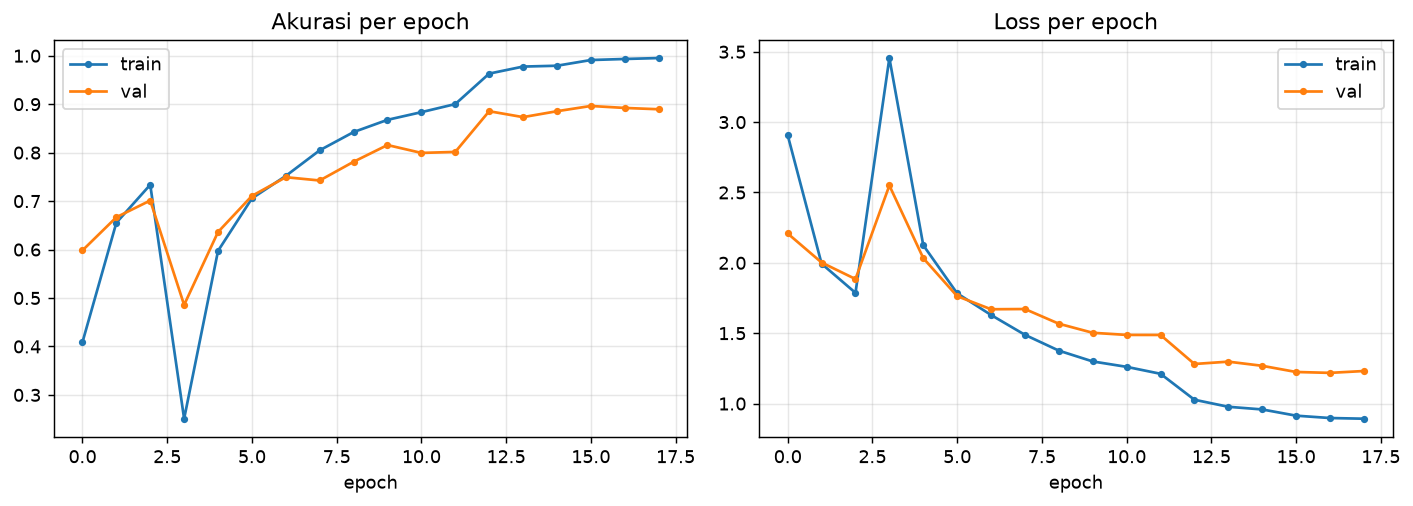

In [38]:
# ---------- kurva training ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["accuracy"], label="train", marker="o", ms=3)
ax[0].plot(hist["val_accuracy"], label="val", marker="o", ms=3)
ax[0].set_title("Akurasi per epoch"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(hist["loss"], label="train", marker="o", ms=3)
ax[1].plot(hist["val_loss"], label="val", marker="o", ms=3)
ax[1].set_title("Loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3); ax[1].legend()
show_fig(fig, FIG / "kurva_training.png", dpi=130)


**Penjelasan output (grafik):** dua kurva training. Kiri: akurasi train vs val per epoch, terlihat train terus naik ke ~99,5% sementara val mendatar di ~89%. Kanan: loss train vs val, val berhenti turun setelah sekitar epoch 10. Pola ini menunjukkan model mulai menghafal data latih, sehingga yang dipakai adalah bobot val terbaik.

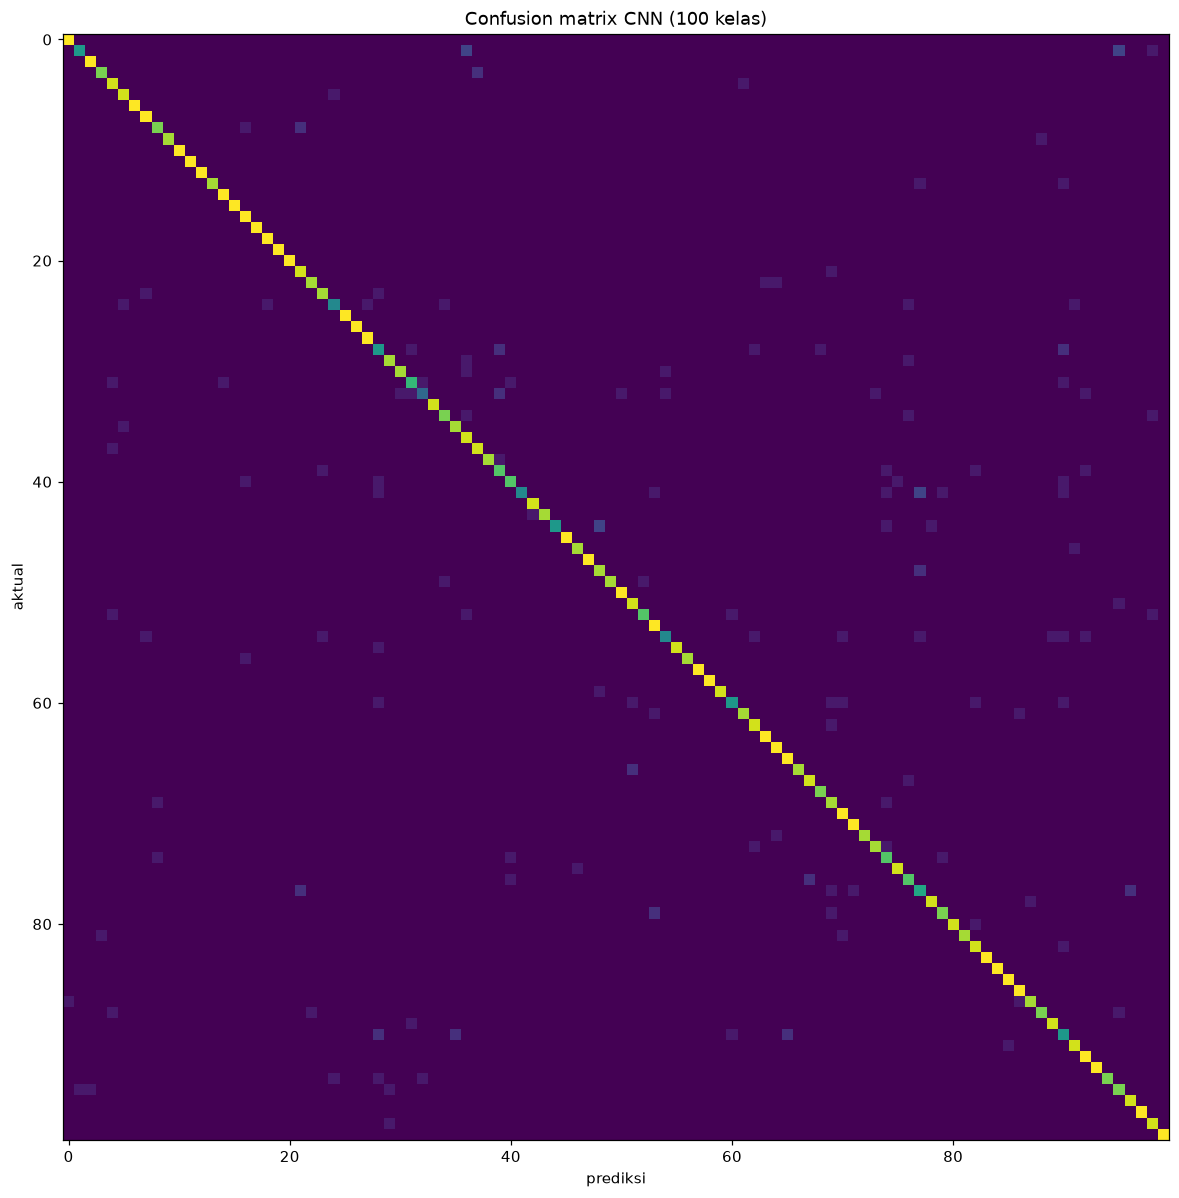

In [39]:
# ---------- confusion matrix ----------
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(cm, cmap="viridis")
ax.set_title(f"Confusion matrix CNN ({N} kelas)")
ax.set_xlabel("prediksi"); ax.set_ylabel("aktual")
show_fig(fig, FIG / "confusion_matrix.png", dpi=110)


**Penjelasan output (grafik):** confusion matrix 100×100. Sumbu Y adalah kelas asli, sumbu X adalah tebakan model. Warna terang di diagonal berarti tebakan benar; titik terang di luar diagonal adalah kesalahan. Diagonal tampak dominan, jadi sebagian besar kelas dikenali dengan baik, dan kesalahan yang ada menyebar tipis, bukan menumpuk di satu pasangan kelas.

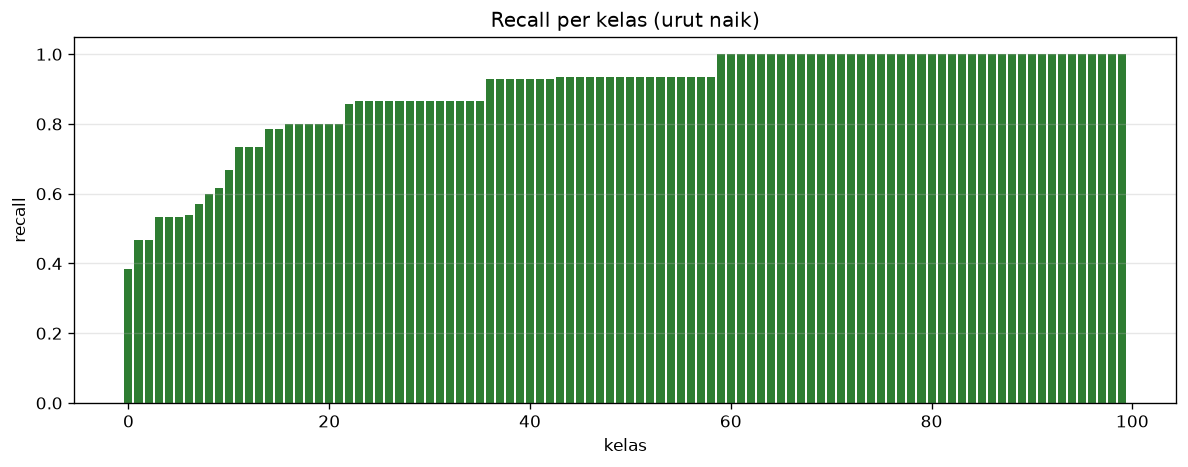

In [40]:
# ---------- recall per kelas ----------
order = np.argsort(per_class)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(per_class)), per_class[order], color="#2e7d32")
ax.set_title("Recall per kelas (urut naik)"); ax.set_xlabel("kelas"); ax.set_ylabel("recall")
ax.grid(axis="y", alpha=.3)
show_fig(fig, FIG / "recall_per_kelas.png", dpi=120)


**Penjelasan output (grafik):** grafik recall per kelas, diurutkan dari terendah ke tertinggi. Setiap batang satu spesies. Batang paling kiri adalah kelas yang paling sering salah, sedangkan mayoritas batang di kanan mendekati 100%. Grafik ini memperlihatkan bahwa masalah utama bukan rata-rata akurasi, melainkan beberapa kelas sulit tertentu.

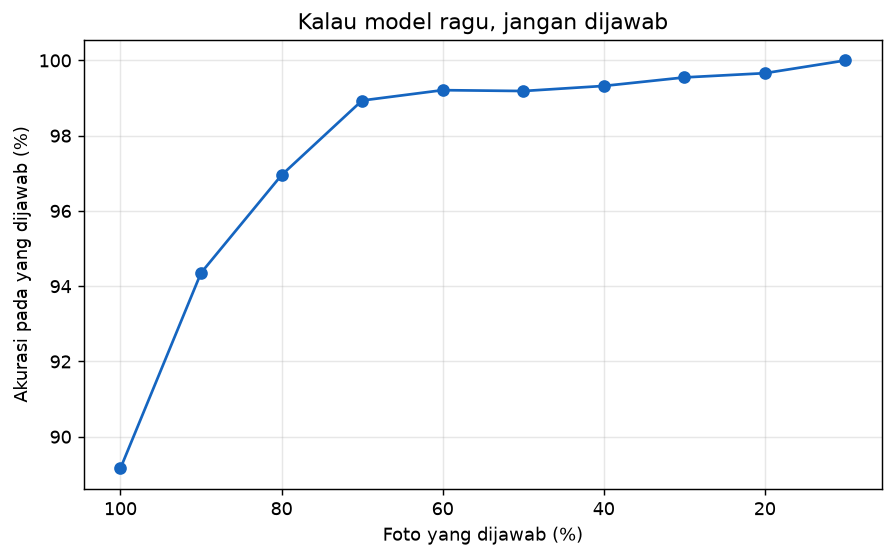

In [41]:
# ---------- kurva abstain ----------
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(cur.coverage * 100, cur.accuracy * 100, marker="o", color="#1565c0")
ax.set_xlabel("Foto yang dijawab (%)"); ax.set_ylabel("Akurasi pada yang dijawab (%)")
ax.set_title("Kalau model ragu, jangan dijawab"); ax.invert_xaxis(); ax.grid(alpha=.3)
show_fig(fig, FIG / "kurva_abstain.png", dpi=130)


**Penjelasan output (grafik):** kurva abstain — sumbu X adalah persentase foto yang mau dijawab, sumbu Y akurasi pada foto yang dijawab. Kurva naik dari kiri ke kanan artinya: semakin banyak foto yang ditolak, semakin tinggi akurasi sisanya. Ini dasar aturan "kalau ragu jangan dijawab".

### 2.5 Tabel Ringkasan Model 1

In [42]:
# ---------- tabel ringkasan ----------
ringkasan = pd.DataFrame({
    "Metrik": ["Top-1", "Top-3", "Macro-F1", "Resolusi input", "Parameter", "Ukuran model"],
    "Nilai": [f"{m['top1']:.1%}", f"{m['top3']:.1%}", f"{m['macro_f1']:.1%}",
              f"{m['img']}x{m['img']}", f"{m['n_params']:,}",
              f"{(D / 'model.keras').stat().st_size / 1024**2:.1f} MB"],
})
tampil("Ringkasan model 1", ringkasan)


**Ringkasan model 1**

,Metrik,Nilai
0,Top-1,89.2%
1,Top-3,95.3%
2,Macro-F1,88.8%
3,Resolusi input,224x224
4,Parameter,"2,386,084"
5,Ukuran model,23.3 MB


**Penjelasan output (tabel):** tabel ringkasan Model 1. Top-1 89,2%, Top-3 95,3%, Macro-F1 88,8% pada input 224×224. Model punya 2.386.084 parameter dan ukuran file Keras 23,3 MB — besar karena masih float32; versi TFLite float16 nanti hanya 4,56 MB.

In [43]:
# ---------- tabel keamanan ----------
keamanan = pd.DataFrame({
    "Metrik": ["Foto beracun di test", "Dikenali sebagai beracun",
               "Kesalahan fatal (beracun -> pangan)", "Recall pangan",
               "Alarm beracun palsu pada pangan"],
    "Nilai": [m["n_test_beracun"], f"{m['recall_beracun_sebagai_beracun']:.1%}",
              f"{m['fatal_n']} = {m['fatal_rate']:.1%}", f"{m['recall_pangan']:.1%}",
              f"{m['alarm_palsu_beracun_pada_pangan']:.1%}"],
})
tampil("Keamanan", keamanan)


**Keamanan**

,Metrik,Nilai
0,Foto beracun di test,444
1,Dikenali sebagai beracun,92.3%
2,Kesalahan fatal (beracun -> pangan),19 = 4.3%
3,Recall pangan,96.3%
4,Alarm beracun palsu pada pangan,13.9%


**Penjelasan output (tabel):** metrik keamanan Model 1 tanpa aturan penolakan. Dari 444 foto beracun di test, 92,3% dikenali sebagai beracun, tetapi 19 foto (4,3%) salah ditebak sebagai pangan — inilah kesalahan fatal. `Recall pangan 96,3%` berarti tanaman pangan hampir tidak pernah hilang. `Alarm beracun palsu 13,9%` berarti sebagian tanaman pangan ditandai beracun; ini merugikan tapi tidak berbahaya.

In [44]:
# ---------- tabel kurva abstain ----------
tampil("Akurasi vs cakupan",
       cur.rename(columns={"coverage": "cakupan", "accuracy": "akurasi", "n": "jumlah"}))


**Akurasi vs cakupan**

,cakupan,akurasi,jumlah
0,1.0,0.891599,1476
1,0.9,0.943524,1328
2,0.8,0.969517,1181
3,0.7,0.989351,1033
4,0.6,0.992099,886
5,0.5,0.991870,738
6,0.4,0.993220,590
7,0.3,0.995485,443
8,0.2,0.996610,295
9,0.1,1.000000,148


**Penjelasan output (tabel):** hubungan antara cakupan dan akurasi Model 1. Pada `cakupan 1.0` (semua 1.476 foto dijawab) akurasi 89,2%. Kalau hanya 90% foto paling yakin yang dijawab, akurasi naik ke 94,4%, dan pada 10% teratas mencapai 100%. Kolom `jumlah` adalah banyaknya foto yang dijawab. Tabel ini yang nanti dipakai memilih `AMBANG`.

In [45]:
# ---------- tabel kelas terburuk ----------
tampil("15 kelas terburuk", wk)


**15 kelas terburuk**

,spesies,recall,n
32,Dioscorea Hispida (Gadung),0.384615,13
41,Gynura Segetum (Daun Dewa),0.466667,15
54,Merremia Mammosa (Bidara),0.466667,15
1,Acorus Calamus (Dlingo),0.533333,15
28,Cyclea Barbata (Cincau Hijau),0.533333,15
90,Syzygium Polyanthum (Salam),0.533333,15
24,Clinalanthus Nutans (Dandang Gendis),0.538462,13
60,Murraya Koenigii (Daun Kari),0.571429,14
77,Pluchea Indica (Beluntas),0.600000,15
44,Houttoynia Cordata (Amis-Amisan),0.615385,13


**Penjelasan output (tabel):** 15 kelas dengan recall terendah. `Dioscorea Hispida (Gadung)` paling buruk: hanya 38,5% dari 13 fotonya dikenali benar. Kolom `n` adalah jumlah foto kelas itu di test (13–15 foto karena test 1.476 ÷ 100 kelas). Daftar ini penting karena Gadung adalah tanaman beracun, jadi kesulitan di kelas ini berisiko tinggi.

---

# Tahap 3 · Model 2 — SVM RBF di atas embedding CNN

SVM tidak melihat gambar, melainkan vektor 1.280 dimensi dari lapisan `embedding` model 1.

**Tujuan:** membandingkan classifier non-linear klasik dengan CNN pada fitur yang sama.

**Yang dilakukan:** standarisasi fitur, kernel RBF `C=10`, 100 kelas one-vs-rest. Skor keputusan diubah ke probabilitas dengan softmax bertemperatur supaya kurva abstainnya bisa dibandingkan.

### 3.1 Melatih SVM

Fitur embedding distandarkan lalu SVM RBF dilatih untuk 100 kelas.

In [46]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import (OUT, abstain_curve, load_labels, load_tags, safety_metrics,  # noqa: E402
                    save_json, show_fig, tampil, topk_acc, worst_classes)

import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

SRC = OUT / "01_cnn"
D = OUT / "02_svm"
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [47]:
labels = load_labels()
N = len(labels)
Xtr, Xva, Xte = (np.load(SRC / "emb_train.npy"), np.load(SRC / "emb_val.npy"),
                 np.load(SRC / "emb_test.npy"))
ytr, yva, yte = (np.load(SRC / "y_train.npy"), np.load(SRC / "y_val.npy"),
                 np.load(SRC / "y_test.npy"))
print(f"embedding train {Xtr.shape} test {Xte.shape} | kelas {N}", flush=True)

embedding train (6887, 1280) test (1476, 1280) | kelas 100


**Penjelasan output (log):** bentuk fitur yang dipakai SVM. Train (6.887 × 1.280) dan test (1.476 × 1.280) — 1.280 adalah panjang vektor embedding keluaran CNN, bukan piksel gambar. `kelas 100` memastikan jumlah label sesuai. SVM memang tidak melihat gambar langsung, hanya deskripsi angka ini.

In [48]:
t0 = time.time()
pipe = make_pipeline(StandardScaler(),
                     SVC(C=10, gamma="scale", kernel="rbf",
                         decision_function_shape="ovr", cache_size=3000))
pipe.fit(Xtr, ytr)
train_sec = time.time() - t0
print(f"fit SVM: {train_sec/60:.1f} menit", flush=True)

fit SVM: 0.7 menit


**Penjelasan output (log):** `fit SVM: 0.7 menit`. Melatih 100 classifier RBF one-vs-rest di 6.887 baris fitur hanya butuh kurang dari satu menit, jauh lebih cepat daripada training CNN 60 menit. Ini karena SVM bekerja di ruang fitur 1.280 dimensi yang sudah diringkas CNN.

In [49]:
score = pipe.decision_function(Xte)
pred = score.argmax(1)

# skor -> pseudo-probabilitas (softmax bertemperatur) supaya kurva abstain sebanding

In [50]:
def to_prob(s, T=10.0):
    z = s / T
    z -= z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)

In [51]:
probs = to_prob(score)
top1 = accuracy_score(yte, pred)
top3 = topk_acc(yte, probs, 3)
macro = f1_score(yte, pred, average="macro")

In [52]:
np.save(D / "skor_keputusan_test.npy", score)
np.save(D / "probabilitas_test.npy", probs)
np.save(D / "pred_test.npy", pred)

In [53]:
tags = load_tags()
safe, fatal = safety_metrics(yte, pred, labels, tags)
metrics = {"model": "SVM RBF (embedding CNN)", "top1": float(top1), "top3": float(top3),
           "macro_f1": float(macro), "train_sec": round(train_sec, 1), **safe}

In [54]:
save_json(D / "metrics.json", metrics)
print(f"TOPI-1 {top1:.4f} | TOP-3 {top3:.4f} | macroF1 {macro:.4f}", flush=True)

cm = confusion_matrix(yte, pred, labels=list(range(N)))

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\02_svm\metrics.json
TOPI-1 0.8991 | TOP-3 0.9566 | macroF1 0.8966


**Penjelasan output (hasil metrik):** metrik SVM di data test. Top-1 89,91%, Top-3 95,66%, Macro-F1 89,66% — sedikit di atas CNN pada Top-1 dan Top-3. Angka ini dicetak setelah `metrics.json` tersimpan, jadi hasil di notebook dan file serah terima berasal dari perhitungan yang sama.

### 3.2 Grafik Evaluasi SVM

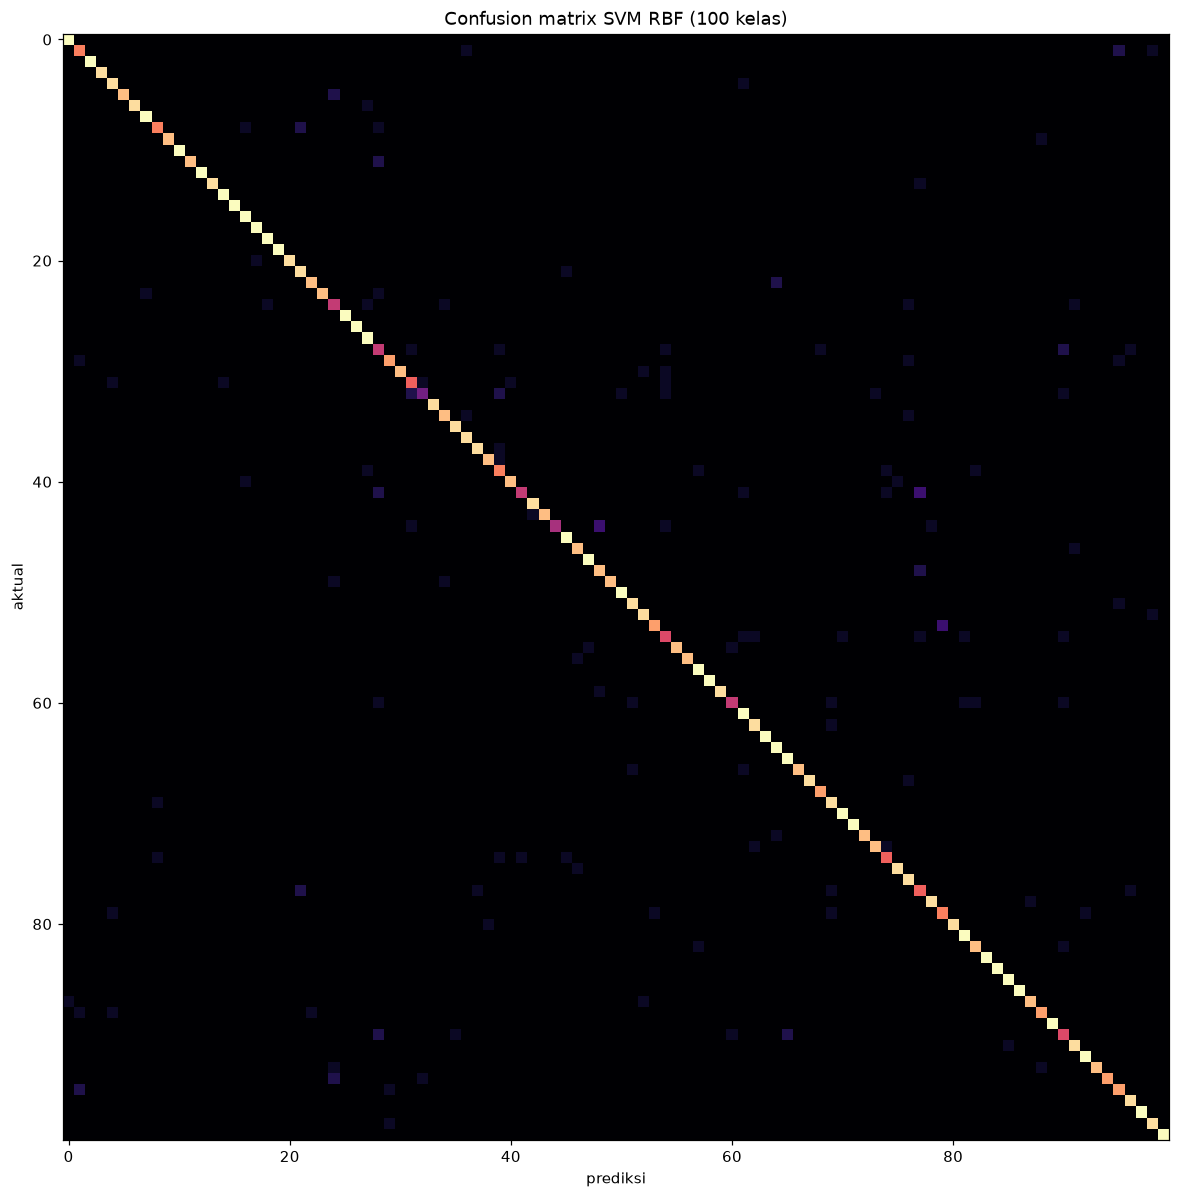

In [55]:
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(cm, cmap="magma")
ax.set_title("Confusion matrix SVM RBF (100 kelas)"); ax.set_xlabel("prediksi"); ax.set_ylabel("aktual")
show_fig(fig, FIG / "confusion_matrix.png", dpi=110)

**Penjelasan output (grafik):** confusion matrix SVM. Polanya mirip CNN: diagonal dominan dan kesalahan menyebar. Perbedaannya halus, karena SVM memakai embedding CNN yang sama, jadi kesulitannya cenderung di kelas yang sama.

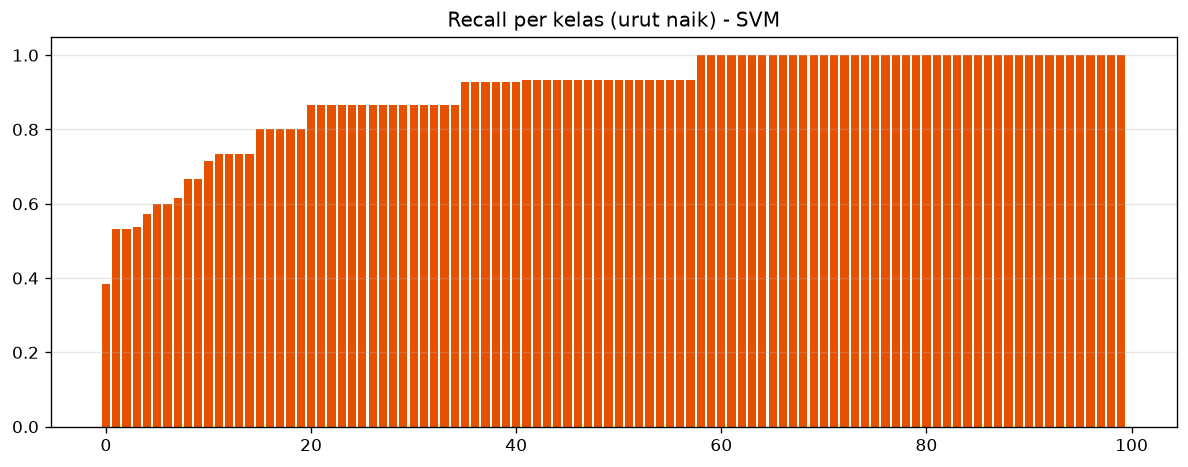

In [56]:
per_class = cm.diagonal() / np.maximum(cm.sum(1), 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(per_class)), per_class[np.argsort(per_class)], color="#e65100")
ax.set_title("Recall per kelas (urut naik) - SVM"); ax.grid(axis="y", alpha=.3)
show_fig(fig, FIG / "recall_per_kelas.png", dpi=120)

**Penjelasan output (grafik):** recall per kelas untuk SVM, urut dari terburuk. Dibandingkan CNN, batang paling kiri sedikit lebih tinggi, artinya SVM sedikit lebih baik di kelas tersulit. Tetap ada kelas yang recall-nya jauh di bawah rata-rata, jadi tidak ada model yang sempurna di 100 kelas.

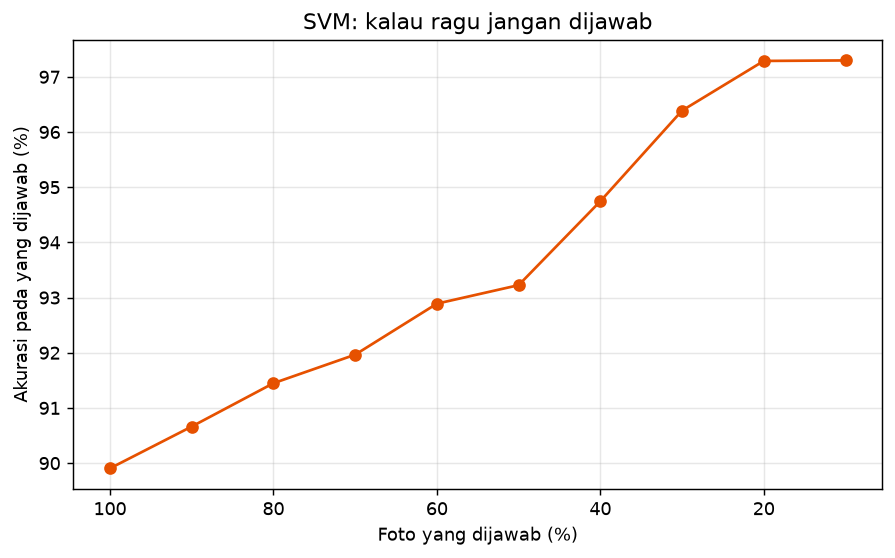

In [57]:
cur = abstain_curve(yte, pred, probs.max(1))
cur.to_csv(D / "kurva_abstain.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(cur.coverage * 100, cur.accuracy * 100, marker="o", color="#e65100")
ax.set_xlabel("Foto yang dijawab (%)"); ax.set_ylabel("Akurasi pada yang dijawab (%)")
ax.set_title("SVM: kalau ragu jangan dijawab"); ax.invert_xaxis(); ax.grid(alpha=.3)
show_fig(fig, FIG / "kurva_abstain.png", dpi=130)

**Penjelasan output (grafik):** kurva abstain SVM. Bentuknya menanjak seperti CNN, artinya probabilitas SVM juga bisa dipakai untuk menolak foto yang meragukan. Catatan teknis: probabilitas SVM di sini hasil softmax bertemperatur dari `decision_function`, jadi angkanya tidak sebanding langsung dengan probabilitas CNN — hanya bentuk kurvanya yang dibandingkan.

In [58]:
wk, best = worst_classes(yte, pred, labels, 15)
wk.to_csv(D / "kelas_terburuk.csv", index=False)

# --- tabel ringkasan ---
ringkasan = pd.DataFrame({
    "Metrik": ["Top-1", "Top-3", "Macro-F1", "Waktu fit", "Input"],
    "Nilai": [f"{top1:.1%}", f"{top3:.1%}", f"{macro:.1%}",
              f"{train_sec/60:.1f} menit", "embedding 1.280 dimensi dari model 1"],
})
tampil("Ringkasan model 2", ringkasan)

**Ringkasan model 2**

,Metrik,Nilai
0,Top-1,89.9%
1,Top-3,95.7%
2,Macro-F1,89.7%
3,Waktu fit,0.7 menit
4,Input,embedding 1.280 dimensi dari model 1


**Penjelasan output (tabel):** tabel ringkasan SVM. Top-1 89,9%, Top-3 95,7%, Macro-F1 89,7%, waktu fit 0,7 menit, dan inputnya embedding 1.280 dimensi dari Model 1. Ukuran tidak dicantumkan di sini karena dihitung terpisah pada Tahap 6b.

### 3.3 Tabel Hasil SVM

In [59]:
# --- tabel keamanan ---
keamanan = pd.DataFrame({
    "Metrik": ["Foto beracun di test", "Dikenali sebagai beracun",
               "Kesalahan fatal", "Recall pangan", "Alarm beracun palsu pada pangan"],
    "Nilai": [safe['n_test_beracun'], f"{safe['recall_beracun_sebagai_beracun']:.1%}",
              f"{safe['fatal_n']} = {safe['fatal_rate']:.1%}", f"{safe['recall_pangan']:.1%}",
              f"{safe['alarm_palsu_beracun_pada_pangan']:.1%}"],
})
tampil("Keamanan", keamanan)

**Keamanan**

,Metrik,Nilai
0,Foto beracun di test,444
1,Dikenali sebagai beracun,92.8%
2,Kesalahan fatal,16 = 3.6%
3,Recall pangan,96.2%
4,Alarm beracun palsu pada pangan,13.7%


**Penjelasan output (tabel):** metrik keamanan SVM. Kesalahan fatal turun ke 16 = 3,6% (CNN 19 = 4,3%), jadi SVM sedikit lebih aman. Namun `Recall pangan 96,2%` dan `alarm beracun palsu 13,7%` hampir sama dengan CNN. Keunggulan SVM di sini tipis dan tidak cukup untuk mengalahkan masalah ukuran modelnya.

In [60]:
# --- tabel kurva abstain ---
tampil("Akurasi vs cakupan", cur.rename(columns={"coverage": "cakupan",
                                                 "accuracy": "akurasi", "n": "jumlah"}))

**Akurasi vs cakupan**

,cakupan,akurasi,jumlah
0,1.0,0.899051,1476
1,0.9,0.906627,1328
2,0.8,0.914479,1181
3,0.7,0.919652,1033
4,0.6,0.928894,886
5,0.5,0.932249,738
6,0.4,0.947458,590
7,0.3,0.963883,443
8,0.2,0.972881,295
9,0.1,0.972973,148


**Penjelasan output (tabel):** akurasi vs cakupan untuk SVM. Pada cakupan 100% akurasi 89,9%; pada cakupan 60% menjadi 92,9%; pada 10% teratas 97,3%. Dibandingkan CNN, kurva SVM naik lebih landai, sehingga pada cakupan yang sama (misalnya 90%) CNN justru lebih akurat. Ini alasan keputusan akhir memilih CNN.

In [61]:
# --- tabel kelas terburuk ---
tampil("15 kelas terburuk", wk)
print("DONE MODEL 2", flush=True)

**15 kelas terburuk**

,spesies,recall,n
32,Dioscorea Hispida (Gadung),0.384615,13
28,Cyclea Barbata (Cincau Hijau),0.533333,15
41,Gynura Segetum (Daun Dewa),0.533333,15
44,Houttoynia Cordata (Amis-Amisan),0.538462,13
60,Murraya Koenigii (Daun Kari),0.571429,14
54,Merremia Mammosa (Bidara),0.600000,15
90,Syzygium Polyanthum (Salam),0.600000,15
24,Clinalanthus Nutans (Dandang Gendis),0.615385,13
77,Pluchea Indica (Beluntas),0.666667,15
31,Desmodium Triquitrum (Daun Duduk),0.666667,15


DONE MODEL 2


**Penjelasan output (log + tabel):** 15 kelas terburuk versi SVM. `Dioscorea Hispida (Gadung)` tetap paling buruk (38,5%), sama seperti versi CNN. Kesamaan ini menunjukkan kesulitan ada di fiturnya (bentuk daun Gadung mirip kencur), bukan semata di classifier-nya. `DONE MODEL 2` menandai tahap selesai.

---

# Tahap 4 · Model 3 — Random Forest 300 pohon

Random Forest memakai embedding yang sama dengan SVM, jadi perbandingannya apple-to-apple.

**Tujuan:** melihat performa ensemble pohon sebagai pembanding kedua.

**Yang dilakukan:** 300 pohon dengan `class_weight=balanced_subsample`. Ukuran model ikut diukur karena ini penentu apakah layak dibawa ke HP.

### 4.1 Melatih Random Forest

300 pohon di atas embedding yang sama, sekaligus mengukur ukuran model.

In [62]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import (OUT, abstain_curve, load_labels, load_tags, safety_metrics,  # noqa: E402
                    save_json, show_fig, tampil, topk_acc, worst_classes)

import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

SRC = OUT / "01_cnn"
D = OUT / "03_rf"
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [63]:
labels = load_labels()
N = len(labels)
Xtr = np.load(SRC / "emb_train.npy")
Xte = np.load(SRC / "emb_test.npy")
ytr = np.load(SRC / "y_train.npy")
yte = np.load(SRC / "y_test.npy")
print(f"embedding train {Xtr.shape} test {Xte.shape} | kelas {N}", flush=True)

embedding train (6887, 1280) test (1476, 1280) | kelas 100


**Penjelasan output (log):** bentuk fitur untuk Random Forest, identik dengan SVM: train 6.887 × 1.280 dan test 1.476 × 1.280, 100 kelas. Karena memakai fitur yang sama persis, perbandingan Random Forest vs SVM vs CNN adil (apple to apple): yang berbeda hanya algoritmanya.

In [64]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", n_jobs=-1,
                            random_state=42, class_weight="balanced_subsample")
rf.fit(Xtr, ytr)
train_sec = time.time() - t0
print(f"fit RF: {train_sec/60:.1f} menit", flush=True)

fit RF: 0.6 menit


**Penjelasan output (log):** `fit RF: 0.6 menit` untuk 300 pohon. Random Forest bahkan sedikit lebih cepat dari SVM di sini, tapi kecepatan melatih bukan masalah utama — yang menentukan adalah ukuran model setelah jadi.

In [65]:
probs = rf.predict_proba(Xte)
pred = probs.argmax(1)
top1 = accuracy_score(yte, pred)
top3 = topk_acc(yte, probs, 3)
macro = f1_score(yte, pred, average="macro")

# ukuran forest: diukur, bukan diperkirakan
n_nodes = int(sum(t.tree_.node_count for t in rf.estimators_))
n_leaves = int(sum(int((t.tree_.children_left == -1).sum()) for t in rf.estimators_))
# sklearn menyimpan tabel 100 kelas di SETIAP node (float64) -> besar sekali
size_sklearn_mb = sum(
    t.tree_.value.nbytes + sum(
        getattr(t.tree_, a).nbytes for a in
        ("children_left", "children_right", "feature", "threshold",
         "impurity", "n_node_samples", "weighted_n_node_samples"))
    for t in rf.estimators_) / 1024 ** 2
# format padat: 14 byte/node + distribusi kelas hanya di leaf (float32)
size_padat_mb = (n_nodes * 14 + n_leaves * N * 4) / 1024 ** 2

In [66]:
np.save(D / "probabilitas_test.npy", probs)
np.save(D / "pred_test.npy", pred)

tags = load_tags()
safe, fatal = safety_metrics(yte, pred, labels, tags)

In [67]:
metrics = {"model": "Random Forest 300", "top1": float(top1), "top3": float(top3),
           "macro_f1": float(macro), "train_sec": round(train_sec, 1),
           "n_nodes": n_nodes, "n_leaves": n_leaves,
           "size_sklearn_mb": round(size_sklearn_mb, 1),
           "size_padat_mb": round(size_padat_mb, 1), **safe}

In [68]:
save_json(D / "metrics.json", metrics)
print(f"TOPI-1 {top1:.4f} | TOP-3 {top3:.4f} | macroF1 {macro:.4f}", flush=True)
print(f"node {n_nodes:,} | sklearn {size_sklearn_mb:.0f} MB | padat {size_padat_mb:.0f} MB",
      flush=True)

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\03_rf\metrics.json
TOPI-1 0.8720 | TOP-3 0.9533 | macroF1 0.8660


node 857,250 | sklearn 700 MB | padat 175 MB


**Penjelasan output (hasil metrik):** metrik Random Forest. Top-1 87,20%, Top-3 95,33%, Macro-F1 86,60% — paling rendah dari ketiganya. Baris berikutnya `node 857,250 | sklearn 700 MB | padat 175 MB` adalah ukuran model: 857.250 node (428.775 daun) membuat file 700 MB di scikit-learn, dan masih 175 MB walau dipadatkan.

### 4.2 Grafik Evaluasi Random Forest

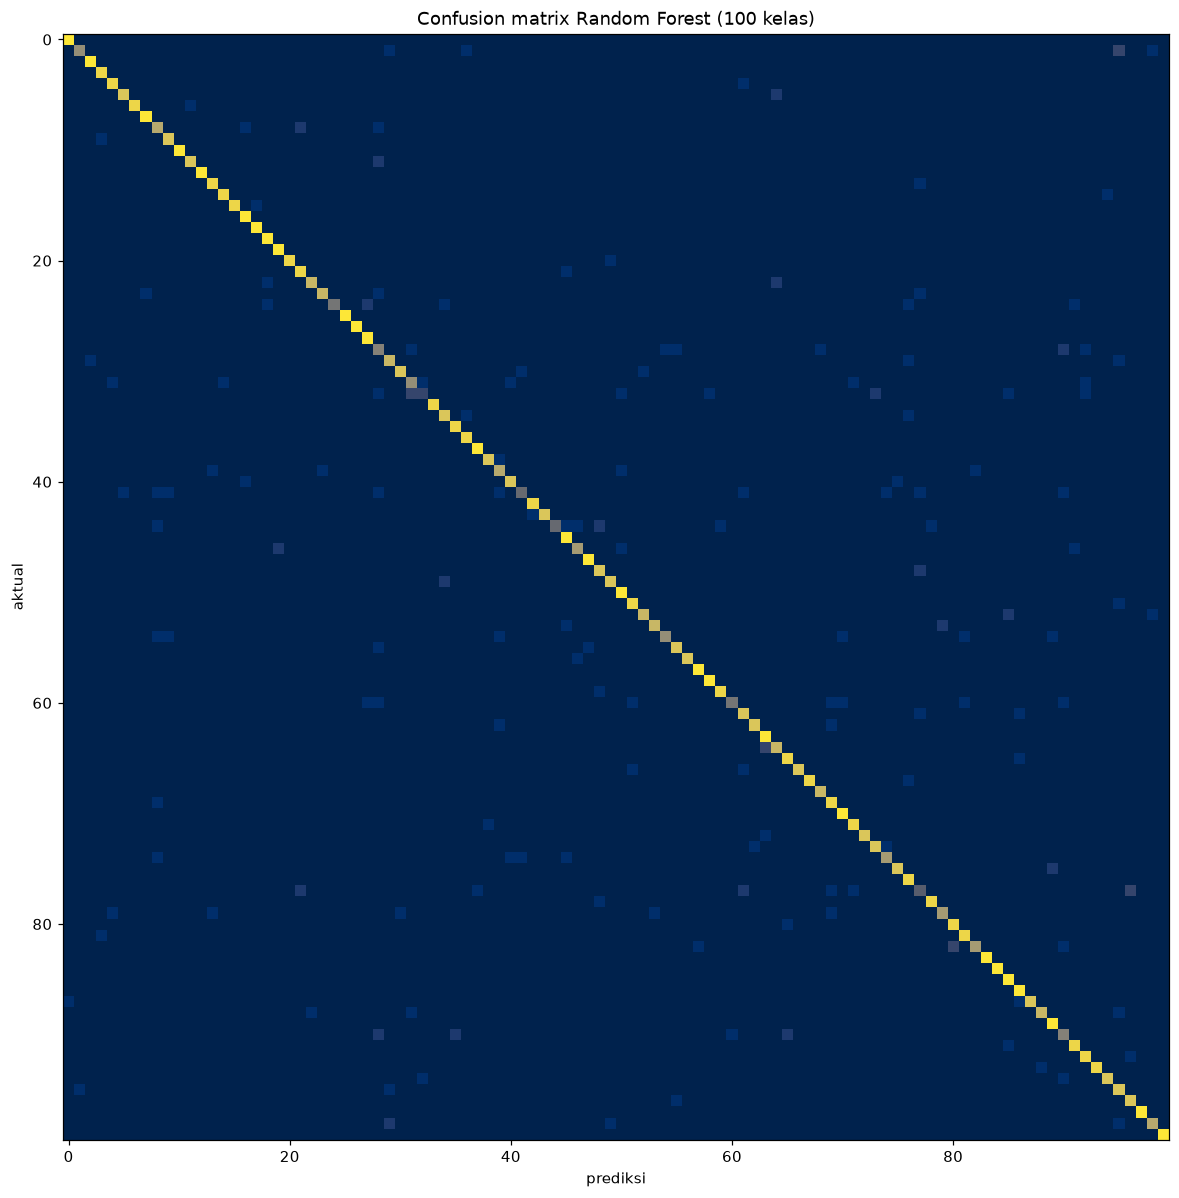

In [69]:
cm = confusion_matrix(yte, pred, labels=list(range(N)))
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(cm, cmap="cividis")
ax.set_title("Confusion matrix Random Forest (100 kelas)")
ax.set_xlabel("prediksi"); ax.set_ylabel("aktual")
show_fig(fig, FIG / "confusion_matrix.png", dpi=110)

**Penjelasan output (grafik):** confusion matrix Random Forest. Diagonal tetap dominan, tetapi titik-titik di luar diagonal lebih banyak dan lebih terang dibanding CNN/SVM. Artinya tebakan salahnya lebih tersebar ke banyak kelas, bukan salah sistematis ke satu kelas tertentu.

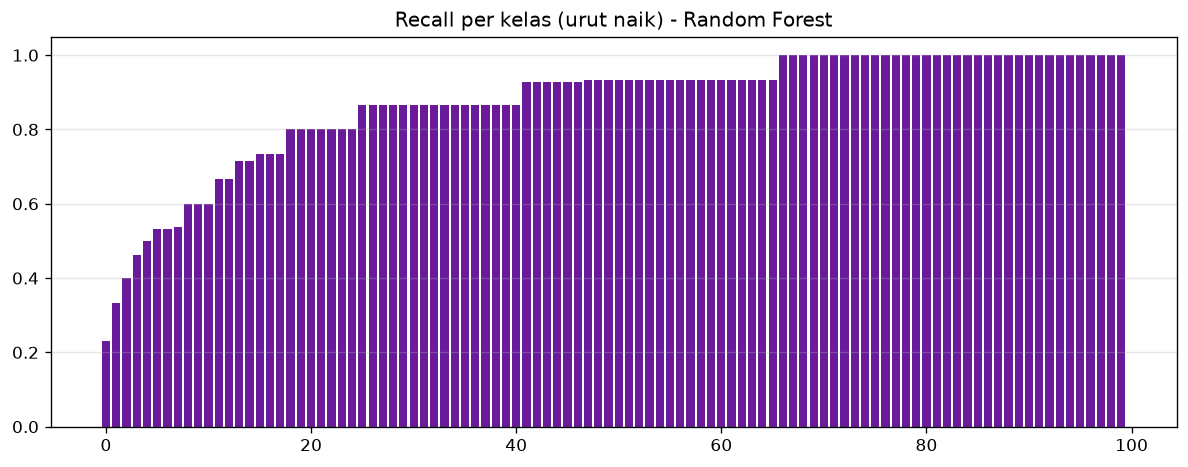

In [70]:
per_class = cm.diagonal() / np.maximum(cm.sum(1), 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(per_class)), per_class[np.argsort(per_class)], color="#6a1b9a")
ax.set_title("Recall per kelas (urut naik) - Random Forest"); ax.grid(axis="y", alpha=.3)
show_fig(fig, FIG / "recall_per_kelas.png", dpi=120)

imp = pd.Series(rf.feature_importances_).sort_values(ascending=False)

**Penjelasan output (grafik):** recall per kelas Random Forest. Batang di sisi kiri lebih rendah dan sebarannya lebih lebar daripada dua model sebelumnya, mengonfirmasi Top-1 yang lebih rendah: beberapa kelas memang jauh lebih sering salah di model ini.

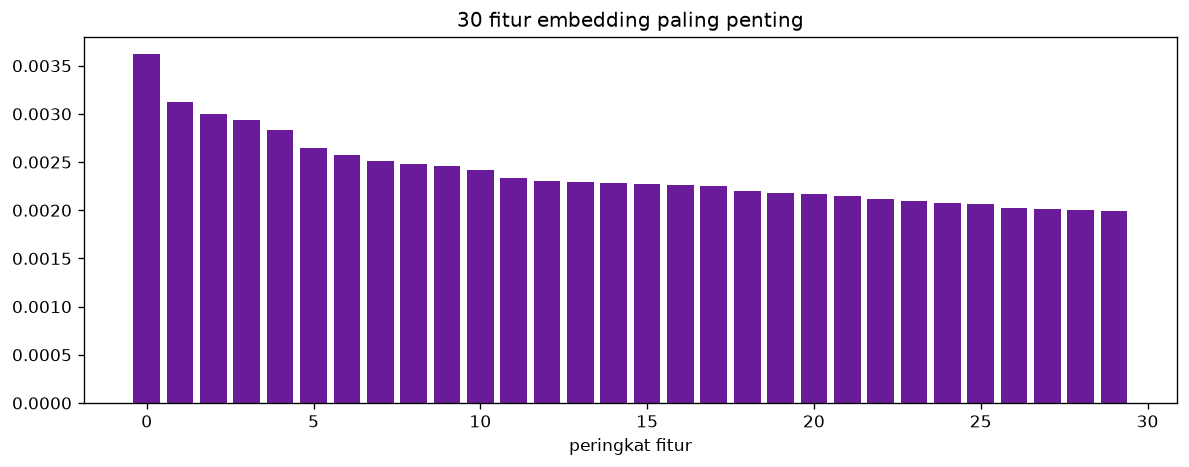

In [71]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(30), imp.values[:30], color="#6a1b9a")
ax.set_title("30 fitur embedding paling penting"); ax.set_xlabel("peringkat fitur")
show_fig(fig, FIG / "fitur_penting.png", dpi=120)

**Penjelasan output (grafik):** 30 fitur (dari 1.280) yang paling sering dipakai Random Forest untuk memisahkan kelas. Sum bu Y = tingkat kepentingan. Sayangnya, kepentingan tinggi pada satu dimensi tidak bisa diterjemahkan menjadi fitur yang bisa ditampilkan ke pengguna, jadi grafik ini hanya menunjukkan model ini benar-benar belajar sesuatu, bukan acak.

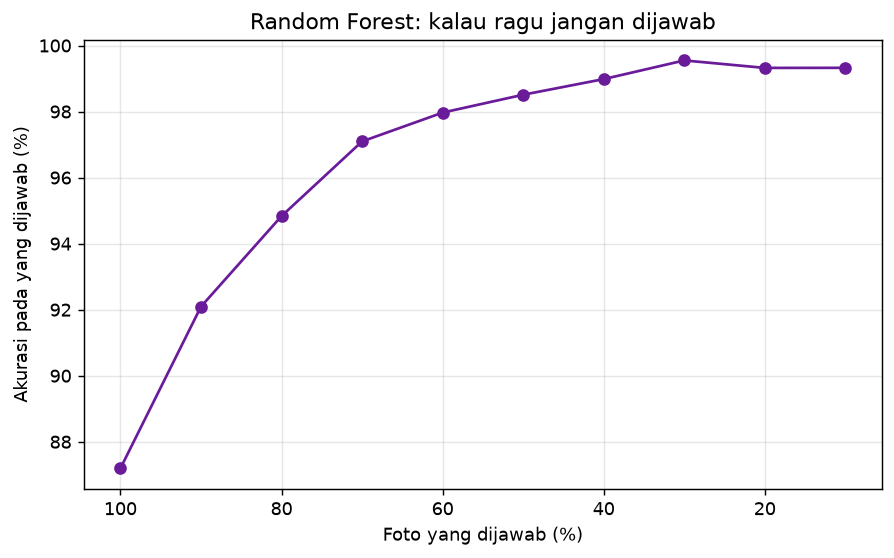

In [72]:
cur = abstain_curve(yte, pred, probs.max(1))
cur.to_csv(D / "kurva_abstain.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(cur.coverage * 100, cur.accuracy * 100, marker="o", color="#6a1b9a")
ax.set_xlabel("Foto yang dijawab (%)"); ax.set_ylabel("Akurasi pada yang dijawab (%)")
ax.set_title("Random Forest: kalau ragu jangan dijawab"); ax.invert_xaxis(); ax.grid(alpha=.3)
show_fig(fig, FIG / "kurva_abstain.png", dpi=130)

**Penjelasan output (grafik):** kurva abstain Random Forest. Kurvanya menanjak paling tajam di awal, yang tampak bagus, tetapi titik awalnya (cakupan 100%) paling rendah (87,2%). Artinya pada cakupan kerja yang dipakai aplikasi (93,4%), Random Forest kalah dari CNN dan SVM.

In [73]:
wk, best = worst_classes(yte, pred, labels, 15)
wk.to_csv(D / "kelas_terburuk.csv", index=False)

# --- tabel ringkasan ---
ringkasan = pd.DataFrame({
    "Metrik": ["Top-1", "Top-3", "Macro-F1", "Waktu fit", "Jumlah pohon",
               "Jumlah node", "Ukuran (scikit-learn)", "Ukuran (format padat)"],
    "Nilai": [f"{top1:.1%}", f"{top3:.1%}", f"{macro:.1%}", f"{train_sec/60:.1f} menit", "300",
              f"{n_nodes:,} ({n_leaves:,} leaf)", f"{size_sklearn_mb:.0f} MB",
              f"{size_padat_mb:.0f} MB"],
})
tampil("Ringkasan model 3", ringkasan)

**Ringkasan model 3**

,Metrik,Nilai
0,Top-1,87.2%
1,Top-3,95.3%
2,Macro-F1,86.6%
3,Waktu fit,0.6 menit
4,Jumlah pohon,300
5,Jumlah node,"857,250 (428,775 leaf)"
6,Ukuran (scikit-learn),700 MB
7,Ukuran (format padat),175 MB


**Penjelasan output (tabel):** tabel ringkasan Random Forest. Top-1 87,2%, Top-3 95,3%, Macro-F1 86,6%, fit 0,6 menit, 300 pohon. Dua baris terakhir adalah masalah utamanya: 857.250 node, 700 MB di scikit-learn, dan 175 MB dalam format padat.

### 4.3 Tabel Hasil Random Forest

In [74]:
# --- tabel keamanan ---
keamanan = pd.DataFrame({
    "Metrik": ["Foto beracun di test", "Dikenali sebagai beracun",
               "Kesalahan fatal", "Recall pangan", "Alarm beracun palsu pada pangan"],
    "Nilai": [safe['n_test_beracun'], f"{safe['recall_beracun_sebagai_beracun']:.1%}",
              f"{safe['fatal_n']} = {safe['fatal_rate']:.1%}", f"{safe['recall_pangan']:.1%}",
              f"{safe['alarm_palsu_beracun_pada_pangan']:.1%}"],
})
tampil("Keamanan", keamanan)

**Keamanan**

,Metrik,Nilai
0,Foto beracun di test,444
1,Dikenali sebagai beracun,91.7%
2,Kesalahan fatal,19 = 4.3%
3,Recall pangan,95.2%
4,Alarm beracun palsu pada pangan,14.2%


**Penjelasan output (tabel):** metrik keamanan Random Forest. Kesalahan fatal 19 = 4,3% (sama dengan CNN, lebih buruk dari SVM), recall pangan 95,2% (paling rendah), dan alarm beracun palsu 14,2% (paling tinggi). Jadi Random Forest bukan pilihan yang baik dari sisi keamanan.

In [75]:
# --- tabel kurva abstain ---
tampil("Akurasi vs cakupan", cur.rename(columns={"coverage": "cakupan",
                                                 "accuracy": "akurasi", "n": "jumlah"}))

**Akurasi vs cakupan**

,cakupan,akurasi,jumlah
0,1.0,0.871951,1476
1,0.9,0.920934,1328
2,0.8,0.948349,1181
3,0.7,0.970958,1033
4,0.6,0.979684,886
5,0.5,0.985095,738
6,0.4,0.989831,590
7,0.3,0.995485,443
8,0.2,0.993220,295
9,0.1,0.993243,148


**Penjelasan output (tabel):** akurasi vs cakupan Random Forest. Di cakupan 100% akurasi 87,2%, cakupan 60% menjadi 98,0%, cakupan 10% 99,3%. Kurvanya naik paling cepat, tetapi karena titik awalnya paling rendah, pada cakupan kerja 93,4% angkanya hanya 90,7% — masih di bawah CNN.

In [76]:
# --- tabel kelas terburuk ---
tampil("15 kelas terburuk", wk)
print("DONE MODEL 3", flush=True)

**15 kelas terburuk**

,spesies,recall,n
32,Dioscorea Hispida (Gadung),0.230769,13
77,Pluchea Indica (Beluntas),0.333333,15
41,Gynura Segetum (Daun Dewa),0.400000,15
44,Houttoynia Cordata (Amis-Amisan),0.461538,13
60,Murraya Koenigii (Daun Kari),0.500000,14
28,Cyclea Barbata (Cincau Hijau),0.533333,15
90,Syzygium Polyanthum (Salam),0.533333,15
24,Clinalanthus Nutans (Dandang Gendis),0.538462,13
54,Merremia Mammosa (Bidara),0.600000,15
31,Desmodium Triquitrum (Daun Duduk),0.600000,15


DONE MODEL 3


**Penjelasan output (log + tabel):** 15 kelas terburuk Random Forest. `Dioscorea Hispida (Gadung)` sangat buruk: hanya 23,1% (2 dari 13 foto benar). Beberapa kelas yang relatif mudah bagi CNN/SVM juga masuk daftar ini, tanda model pohon kurang cocok untuk ruang fitur 1.280 dimensi. `DONE MODEL 3` menandai tahap selesai.

---

# Tahap 5 · Perbandingan 3 Algoritma

Ketiga model diuji di data test yang sama.

**Tujuan:** memilih model yang benar-benar dikirim ke aplikasi.

**Yang dibandingkan:** top-1, top-3, macro-F1, kesalahan fatal (beracun ditebak pangan), alarm palsu, dan akurasi pada cakupan yang dipakai aplikasi.

### 5.1 Menghitung Metrik Ketiga Model

Semua metrik dihitung ulang dari file probabilitas di data test yang sama.

In [77]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import (OUT, load_labels, load_tags, safety_metrics, save_json,  # noqa: E402
                    show_fig, tampil)

import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from sklearn.metrics import accuracy_score, f1_score  # noqa: E402

D = OUT / "04_perbandingan"
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [78]:
labels = load_labels()
tags = load_tags()
yte = np.load(OUT / "01_cnn" / "y_test.npy")

# cakupan dari aturan penolakan (kalau sudah ada) supaya semua model bisa
# dibandingkan pada jumlah foto yang dijawab sama
_rules_f = OUT / "05_bahan_aplikasi" / "safety_rules.json"
RULES = (json.loads(_rules_f.read_text(encoding="utf-8")) if _rules_f.exists() else None)
COV = RULES["test_pada_ambang_ini"]["cakupan"] if RULES else None

models = {
    "CNN MobileNetV2": ("01_cnn", "probabilitas_test.npy"),
    "SVM RBF": ("02_svm", "probabilitas_test.npy"),
    "Random Forest 300": ("03_rf", "probabilitas_test.npy"),
}

In [79]:
rows, curves, percat = [], {}, []
fatal_rows = []
for name, (folder, fname) in models.items():
    p = np.load(OUT / folder / fname)
    pred = p.argmax(1)
    conf = p.max(1)
    safe, fatal = safety_metrics(yte, pred, labels, tags)
    acc_cov = None
    if COV:
        k = int(round(COV * len(yte)))
        sel = np.argsort(-conf)[:k]
        acc_cov = float((pred[sel] == yte[sel]).mean())
    rows.append({
        "model": name,
        "top1": accuracy_score(yte, pred),
        "macro_f1": f1_score(yte, pred, average="macro"),
        "fatal_rate": safe["fatal_rate"],
        "fatal_n": safe["fatal_n"],
        "recall_beracun": safe["recall_beracun_sebagai_beracun"],
        "false_alarm_beracun": safe["alarm_palsu_beracun_pada_pangan"],
        "akurasi_pada_cakupan": acc_cov,
    })
    percat.append({"model": name, **{k: safe[k] for k in
                                     ("recall_pangan", "recall_beracun_sebagai_beracun",
                                      "alarm_palsu_beracun_pada_pangan", "fatal_rate")}})
    cur = pd.read_csv(OUT / folder / "kurva_abstain.csv")
    curves[name] = cur
    for lbl, pr in zip(labels, (pred == yte)):
        pass
    # kesalahan fatal rinci
    tox = np.array([bool(tags.loc[l, "beracun"]) for l in labels])
    food = np.array([bool(tags.loc[l, "pangan"]) for l in labels])
    for i in np.where(fatal)[0]:
        fatal_rows.append({"model": name,
                           "aktual": labels[yte[i]],
                           "ditebak": labels[pred[i]]})

In [80]:
comp = pd.DataFrame(rows)
# top-3 dihitung ulang seragam
t3 = []
for name, (folder, fname) in models.items():
    p = np.load(OUT / folder / fname)
    top = np.argsort(-p, axis=1)[:, :3]
    t3.append(float(np.mean([yte[i] in top[i] for i in range(len(yte))])))
comp["top3"] = t3
comp = comp[["model", "top1", "top3", "macro_f1", "recall_beracun",
             "fatal_rate", "fatal_n", "false_alarm_beracun",
             "akurasi_pada_cakupan"]]

In [81]:
comp.to_csv(D / "tabel_model.csv", index=False)
pd.DataFrame(percat).to_csv(D / "per_kategori.csv", index=False)
pd.DataFrame(fatal_rows).to_csv(D / "kesalahan_fatal.csv", index=False)


### 5.2 Grafik Perbandingan

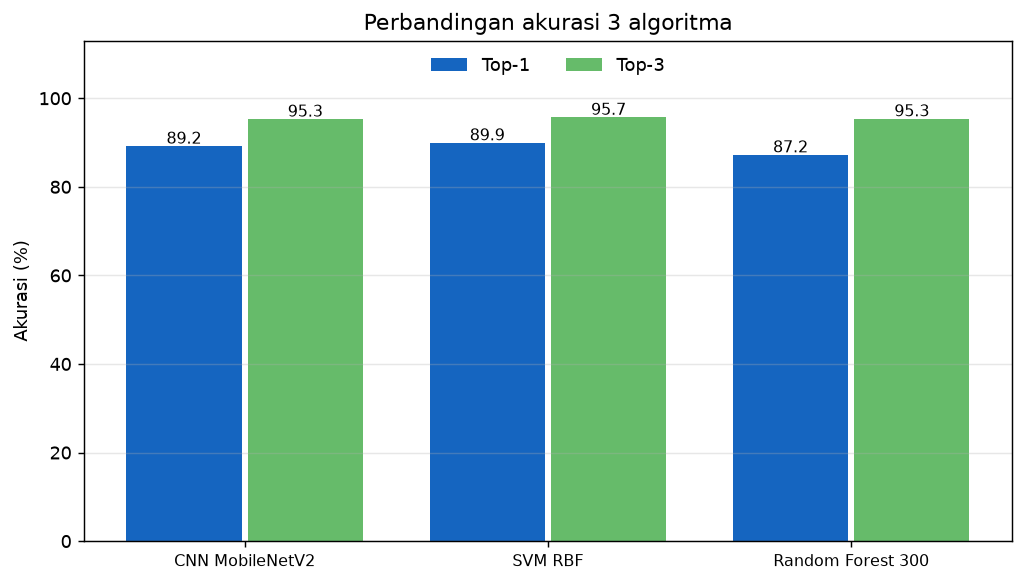

In [82]:
# --- figur: bar akurasi ---
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(comp))
ax.bar(x - 0.2, comp.top1 * 100, width=0.38, label="Top-1", color="#1565c0")
ax.bar(x + 0.2, comp.top3 * 100, width=0.38, label="Top-3", color="#66bb6a")
for i, (a, b) in enumerate(zip(comp.top1, comp.top3)):
    ax.text(i - 0.2, a * 100 + 0.6, f"{a*100:.1f}", ha="center", fontsize=9)
    ax.text(i + 0.2, b * 100 + 0.6, f"{b*100:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(comp.model, fontsize=9)
ax.set_ylabel("Akurasi (%)"); ax.set_ylim(0, 113)
ax.set_title("Perbandingan akurasi 3 algoritma")
ax.legend(loc="upper center", ncol=2, frameon=False)
ax.grid(axis="y", alpha=.3)
show_fig(fig, FIG / "bar_akurasi.png", dpi=130)

**Penjelasan output (grafik):** grafik batang Top-1 ketiga model. SVM RBF 89,9% tertinggi, CNN 89,2% di tengah, Random Forest 87,2% terendah. Selisihnya tipis (2,7 poin antara teratas dan terbawah), jadi Top-1 saja belum cukup untuk memilih model — perlu melihat ukuran dan keamanan.

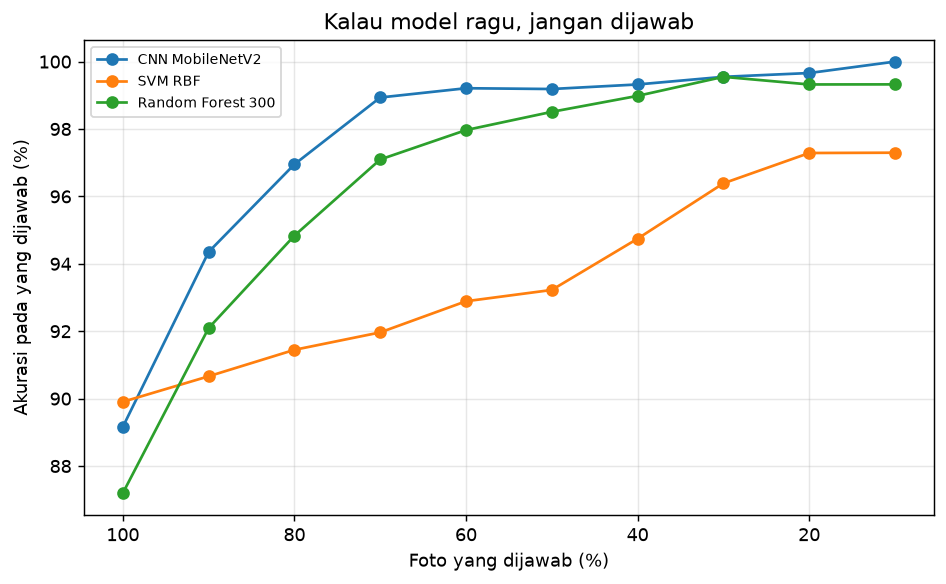

In [83]:
# --- kurva abstain gabungan ---
fig, ax = plt.subplots(figsize=(7.4, 4.6))
for name, cur in curves.items():
    ax.plot(cur.coverage * 100, cur.accuracy * 100, marker="o", label=name)
ax.set_xlabel("Foto yang dijawab (%)"); ax.set_ylabel("Akurasi pada yang dijawab (%)")
ax.set_title("Kalau model ragu, jangan dijawab")
ax.invert_xaxis(); ax.grid(alpha=.3); ax.legend(fontsize=8)
show_fig(fig, FIG / "kurva_abstain_semua.png", dpi=130)

**Penjelasan output (grafik):** ketiga kurva abstain dalam satu grafik. Garis paling atas pada cakupan besar adalah CNN, artinya untuk setiap persentase foto yang dijawab, CNN memberi akurasi tertinggi. Inilah bukti bahwa pada kondisi aplikasi nyata (menolak sebagian foto), CNN unggul walau Top-1 totalnya sedikit di bawah SVM.

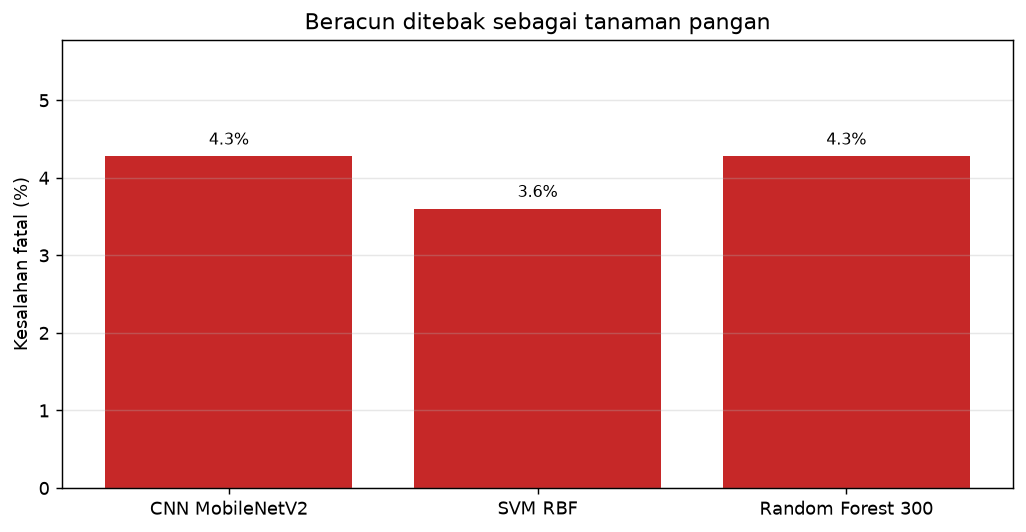

In [84]:
# --- figur fatal ---
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(comp.model, comp.fatal_rate * 100, color="#c62828")
for i, v in enumerate(comp.fatal_rate * 100):
    ax.text(i, v + 0.15, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("Kesalahan fatal (%)")
ax.set_ylim(0, float(comp.fatal_rate.max()) * 100 * 1.35)
ax.set_title("Beracun ditebak sebagai tanaman pangan")
ax.grid(axis="y", alpha=.3)
show_fig(fig, FIG / "kesalahan_fatal.png", dpi=130)

cur_all = pd.concat([c.assign(model=k) for k, c in curves.items()])
cur_all.to_csv(D / "kurva_abstain.csv", index=False)

**Penjelasan output (grafik):** grafik perbandingan kesalahan fatal (beracun ditebak pangan). SVM paling rendah (16 = 3,6%), CNN dan Random Forest sama-sama 19 (4,3%). Karena selisihnya hanya 3 foto dari 444, angka ini tidak cukup kuat untuk menggeser keputusan.

In [85]:
best = comp.sort_values("top1", ascending=False).iloc[0]
row = {r.model: r for r in comp.itertuples()}
cnn = row["CNN MobileNetV2"]
svm = row["SVM RBF"]
rfm = row["Random Forest 300"]
selisih = (svm.top1 - cnn.top1) * 100

In [86]:
def idn(v, d=1):
    return f"{v:.{d}f}".replace(".", ",")


# angka ambang + ukuran diambil dari artefak, bukan ditulis tangan
rules_f = OUT / "05_bahan_aplikasi" / "safety_rules.json"
meta_f = OUT / "05_bahan_aplikasi" / "model_meta.json"
if rules_f.exists():
    _r = json.loads(rules_f.read_text(encoding="utf-8"))
    ambang = _r["ambang_keyakinan"]
    tst = _r["test_pada_ambang_ini"]
    kal_ambang = (f"Dengan `AMBANG = {idn(ambang, 2)}`, "
                  f"{idn(tst['cakupan'] * 100)}% foto dijawab "
                  f"dengan akurasi {idn(tst['akurasi_pada_yang_dijawab'] * 100)}%")
else:
    kal_ambang = "Angka ambang belum dihitung (jalankan `06_threshold.py`)"
ukuran_tflite = (f"{idn(json.loads(meta_f.read_text(encoding='utf-8'))['size_mb'], 2)} MB"
                 if meta_f.exists() else "4,6 MB")
_rf = OUT / "03_rf" / "metrics.json"
if _rf.exists():
    _m = json.loads(_rf.read_text(encoding="utf-8"))
    ukuran_rf = f"{_m.get('size_padat_mb', 175):.0f} MB".replace(".", ",")
else:
    ukuran_rf = "175 MB"

# perbandingan adil: pada cakupan yang sama, siapa paling akurat?
if COV and cnn.akurasi_pada_cakupan is not None:
    kal_cov = (f"Pada cakupan yang sama ({idn(COV * 100)}% foto dijawab), CNN justru "
               f"**paling akurat**: {idn(cnn.akurasi_pada_cakupan * 100)}% "
               f"vs SVM {idn(svm.akurasi_pada_cakupan * 100)}% "
               f"dan RF {idn(rfm.akurasi_pada_cakupan * 100)}%.")
    kal_menang = ("CNN menang setelah aturan penolakan dipakai, jadi SVM tidak "
                  "perlu dibawa ke HP sama sekali.")
    head_cov = f"Akurasi @ cakupan {idn(COV * 100)}%"
    acc_cnn = f"{idn(cnn.akurasi_pada_cakupan * 100)}%"
    acc_svm = f"{idn(svm.akurasi_pada_cakupan * 100)}%"
    acc_rfm = f"{idn(rfm.akurasi_pada_cakupan * 100)}%"
else:
    kal_cov = ("Perbandingan pada cakupan sama belum bisa dihitung karena "
               "`safety_rules.json` belum ada.")
    kal_menang = ""
    head_cov = "Akurasi @ cakupan"
    acc_cnn = acc_svm = acc_rfm = "—"

### 5.3 Tabel Perbandingan

In [87]:
# --- tabel perbandingan ---
comp_tampil = comp.copy()
for _c in ("top1", "top3", "macro_f1", "recall_beracun", "fatal_rate",
           "false_alarm_beracun", "akurasi_pada_cakupan"):
    comp_tampil[_c] = comp_tampil[_c].map(lambda v: "-" if pd.isna(v) else f"{v:.1%}")
tampil("Perbandingan ketiga model di data test", comp_tampil)

**Perbandingan ketiga model di data test**

,model,top1,top3,macro_f1,recall_beracun,fatal_rate,fatal_n,false_alarm_beracun,akurasi_pada_cakupan
0,CNN MobileNetV2,89.2%,95.3%,88.8%,92.3%,4.3%,19,13.9%,92.7%
1,SVM RBF,89.9%,95.7%,89.7%,92.8%,3.6%,16,13.7%,90.6%
2,Random Forest 300,87.2%,95.3%,86.6%,91.7%,4.3%,19,14.2%,90.7%


**Penjelasan output (tabel):** tabel perbandingan lengkap. CNN: Top-1 89,2%, fatal 4,3%, akurasi pada cakupan kerja 92,7%. SVM: Top-1 89,9%, fatal 3,6%, tetapi akurasi pada cakupan kerja hanya 90,6%. RF: Top-1 87,2%, fatal 4,3%, 90,7%. Kolom `akurasi_pada_cakupan` adalah pembanding yang paling jujur karena sesuai kondisi aplikasi yang menolak foto ragu.

In [88]:
# --- tabel pilihan deploy ---
pil = pd.DataFrame([
    ["CNN murni (`model.tflite`)", f"{idn(cnn.top1 * 100)}%", acc_cnn, ukuran_tflite,
     "rendah, 1 inferensi"],
    ["CNN + SVM", f"{idn(svm.top1 * 100)}%", acc_svm, "belasan MB",
     "tinggi, kernel RBF manual"],
    ["CNN + Random Forest", f"{idn(rfm.top1 * 100)}%", acc_rfm, f"+/- {ukuran_rf}",
     "sangat tinggi, tidak layak"],
], columns=["Pilihan", "Top-1 semua foto", head_cov, "Ukuran tambahan", "Kerumitan di aplikasi"])
tampil("Pilihan yang bisa dikirim ke HP", pil)

**Pilihan yang bisa dikirim ke HP**

,Pilihan,Top-1 semua foto,"Akurasi @ cakupan 93,4%",Ukuran tambahan,Kerumitan di aplikasi
0,CNN murni (`model.tflite`),"89,2%","92,7%","4,56 MB","rendah, 1 inferensi"
1,CNN + SVM,"89,9%","90,6%",belasan MB,"tinggi, kernel RBF manual"
2,CNN + Random Forest,"87,2%","90,7%",+/- 175 MB,"sangat tinggi, tidak layak"


**Penjelasan output (tabel):** tabel keputusan pilihan deploy. **CNN murni** hanya 4,56 MB dengan 1 inferensi dan kerumitan rendah. CNN + SVM butuh belasan MB plus implementasi kernel RBF manual di aplikasi. CNN + Random Forest +/- 175 MB dan dinilai tidak layak. Dari sisi akurasi pada cakupan kerja, CNN juga paling tinggi (92,7%), jadi CNN menang tanpa kompromi.

In [89]:
# --- contoh kesalahan fatal ---
if fatal_rows:
    tampil("Contoh kesalahan fatal", pd.DataFrame(fatal_rows).head(15))

**Contoh kesalahan fatal**

,model,aktual,ditebak
0,CNN MobileNetV2,Dioscorea Hispida (Gadung),Kaempferia Galanga (Kencur)
1,CNN MobileNetV2,Gynura Segetum (Daun Dewa),Pluchea Indica (Beluntas)
2,CNN MobileNetV2,Ruta Angustifolia (Inggu),Amaranthus Spinosus (Bayam Duri)
3,CNN MobileNetV2,Typhonium Flagelliforme (Keladi Tikus),Cyclea Barbata (Cincau Hijau)
4,CNN MobileNetV2,Gynura Segetum (Daun Dewa),Melissa officinalis (Lemon Balm)
5,CNN MobileNetV2,Melia Azedarach (Mindi),Murraya Koenigii (Daun Kari)
6,CNN MobileNetV2,Gynura Segetum (Daun Dewa),Syzygium Polyanthum (Salam)
7,CNN MobileNetV2,Alstonia Scholaris (Pulai),Euphoria Longan (Kelengkeng)
8,CNN MobileNetV2,Melia Azedarach (Mindi),Zingiber Officinale (Jahe)
9,CNN MobileNetV2,Gynura Segetum (Daun Dewa),Cyclea Barbata (Cincau Hijau)


**Penjelasan output (tabel):** contoh kesalahan fatal CNN — 15 baris pertama. Kolom `aktual` adalah spesies sebenarnya, `ditebak` adalah tebakan model. Sebagian besar berasal dari kelas beracun yang mirip pangan; contoh paling sering: `Dioscorea Hispida (Gadung)` ditebak `Kaempferia Galanga (Kencur)`. Daftar ini bukan untuk menormalkan kesalahan, tetapi menunjukkan di mana aturan penolakan paling dibutuhkan.

In [90]:
save_json(D / "ringkasan.json", {"tabel": comp.to_dict("records"), "pemenang": best.model})
print("DONE TAHAP 5", flush=True)

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\04_perbandingan\ringkasan.json
DONE TAHAP 5


**Penjelasan output (log):** `DONE TAHAP 5` menandai bahwa tabel perbandingan sudah tersimpan ke `ringkasan.json`. Baris `json -> ...` menyebut lokasi file hasil. Isi file itu sama dengan tabel di atas, dipakai oleh dokumen laporan.

---

# Tahap 6 · Export TFLite float16 + verifikasi

Model 1 dikonversi ke `.tflite` dengan bobot float16 supaya muat anggaran 15 MB.

**Tujuan:** memastikan model yang dikirim ke aplikasi benar-benar sama dengan model yang diuji.

**Yang dilakukan:** konversi float16, lalu 200 gambar test dijalankan di Keras dan di TFLite dan hasil argmax-nya dibandingkan.

### 6.1 Konversi ke TFLite float16

In [91]:
import json
import shutil
import sys
from pathlib import Path

import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import DATA, OUT, save_json, tampil  # noqa: E402

SRC = OUT / "01_cnn"
D = OUT / "05_bahan_aplikasi"
D.mkdir(parents=True, exist_ok=True)

model = tf.keras.models.load_model(SRC / "model.keras")
IMG = int(model.input_shape[1])

In [92]:
labels = json.loads((DATA / "labels.json").read_text(encoding="utf-8"))
print(f"model dimuat | input {model.input_shape} | kelas {len(labels)}", flush=True)

# ---------- konversi ----------
import contextlib
import io

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.target_spec.supported_types = [tf.float16]
_log = io.StringIO()
with contextlib.redirect_stdout(_log), contextlib.redirect_stderr(_log):
    tflite_bytes = conv.convert()
(D / "model.tflite").write_bytes(tflite_bytes)
size_mb = len(tflite_bytes) / 1024 ** 2
print(f"TFLite float16: {size_mb:.2f} MB", flush=True)

model dimuat | input (None, 224, 224, 3) | kelas 100


TFLite float16: 4.56 MB


**Penjelasan output (log):** `model dimuat | input (None, 224, 224, 3) | kelas 100` berarti model Keras berhasil dibuka ulang dengan bentuk input 3 kanal 224×224 (`None` = jumlah batch bebas). `TFLite float16: 4.56 MB` adalah ukuran model setelah dikonversi — turun dari 23,3 MB karena bobotnya disimpan 16-bit.

### 6.2 Verifikasi Keras vs TFLite

In [93]:
# ---------- verifikasi ----------
interp = tf.lite.Interpreter(model_path=str(D / "model.tflite"))
interp.allocate_tensors()
inp_det = interp.get_input_details()[0]
out_det = interp.get_output_details()[0]
print(f"input {inp_det['shape']} {inp_det['dtype']} | output {out_det['shape']}", flush=True)

te = pd.read_csv(DATA / "test.csv")
rng = np.random.default_rng(42)
sample = te.iloc[rng.choice(len(te), size=200, replace=False)]

input [  1 224 224   3] <class 'numpy.float32'> | output [  1 100]


**Penjelasan output (log):** spesifikasi interpreter TFLite yang benar-benar dimuat. Input `[1 224 224 3]` bertipe `float32`, output `[1 100]`. Ini memastikan kontrak ke aplikasi: satu gambar, 224×224, tiga kanal, menghasilkan 100 skor. Urutan 100 skor itu sama dengan urutan `labels.json`.

In [94]:
def load_raw(p):
    raw = tf.io.read_file(str(p))
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG, IMG])
    return tf.cast(img, tf.float32).numpy()[None, ...]


keras_probs, lite_probs = [], []
for p in sample.path.values:
    x = load_raw(p)
    kp = model.predict(x, verbose=0)[0]
    interp.set_tensor(inp_det["index"], x)
    interp.invoke()
    lp = interp.get_tensor(out_det["index"])[0]
    keras_probs.append(kp)
    lite_probs.append(lp)

kp = np.array(keras_probs)
lp = np.array(lite_probs)
agree = float((kp.argmax(1) == lp.argmax(1)).mean())
maxdiff = float(np.abs(kp - lp).max())
meandiff = float(np.abs(kp - lp).mean())
print(f"kesepakatan argmax: {agree:.3%} | max diff {maxdiff:.5f} | mean diff {meandiff:.6f}", flush=True)

y = sample.y.values
acc_keras = float((kp.argmax(1) == y).mean())
acc_lite = float((lp.argmax(1) == y).mean())
print(f"akurasi subset 200 gambar: keras {acc_keras:.3%} | tflite {acc_lite:.3%}", flush=True)

kesepakatan argmax: 100.000% | max diff 0.02470 | mean diff 0.000082


akurasi subset 200 gambar: keras 90.000% | tflite 90.000%


**Penjelasan output (log):** hasil verifikasi Keras vs TFLite pada 200 gambar test. `kesepakatan argmax: 100.000%` berarti keduanya selalu memilih kelas yang sama. `max diff 0.02470` dan `mean diff 0.000082` adalah selisih probabilitas akibat pemotongan float16 — kecil dan tidak mengubah tebakan. Baris terakhir menunjukkan akurasi subset keduanya sama persis, 90,0%. Artinya model yang dikirim setara dengan model yang diuji.

In [95]:
# ---------- aset untuk teman ----------
shutil.copy(DATA / "labels.json", D / "labels.json")
shutil.copy(SRC / "metrics.json", D / "metrics_model_1.json")

meta = {
    "input": {"shape": [1, IMG, IMG, 3], "dtype": "float32",
              "range": "0..255 (jangan dinormalisasi lagi, preprocessing ada di dalam model)",
              "color": "RGB"},
    "output": {"shape": [1, len(labels)], "dtype": "float32", "activation": "softmax",
               "meaning": "probabilitas per kelas, urutan sesuai labels.json"},
    "quantization": "float16 weights",
    "size_mb": round(size_mb, 2),
    "verification": {"n_images": len(sample), "argmax_agreement": agree,
                     "max_abs_diff": maxdiff, "mean_abs_diff": meandiff,
                     "acc_keras_subset": acc_keras, "acc_tflite_subset": acc_lite},
    "labels_count": len(labels),
}

In [96]:
save_json(D / "model_meta.json", meta)

tampil("Verifikasi Keras vs TFLite", pd.DataFrame({
    "Pemeriksaan": ["Kesepakatan argmax (200 gambar)", "Selisih probabilitas maksimum",
                    "Akurasi subset - Keras", "Akurasi subset - TFLite", "Ukuran model"],
    "Hasil": [f"{agree:.2%}", f"{maxdiff:.5f}",
              f"{acc_keras:.1%}", f"{acc_lite:.1%}", f"{size_mb:.2f} MB"],
}))

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\05_bahan_aplikasi\model_meta.json


**Verifikasi Keras vs TFLite**

,Pemeriksaan,Hasil
0,Kesepakatan argmax (200 gambar),100.00%
1,Selisih probabilitas maksimum,0.02470
2,Akurasi subset - Keras,90.0%
3,Akurasi subset - TFLite,90.0%
4,Ukuran model,4.56 MB


**Penjelasan output (log + tabel):** ringkasan verifikasi yang disimpan ke `model_meta.json`: kesepakatan argmax 100%, selisih probabilitas maksimum 0,0247, akurasi subset Keras dan TFLite sama 90,0%, ukuran 4,56 MB. Angka akurasi 90,0% di sini adalah subset 200 gambar, bukan akurasi penuh di 1.476 gambar (89,16%), jadi wajar sedikit berbeda.

In [97]:
# --- tabel kontrak input/output ---
tampil("Kontrak input/output", pd.DataFrame({
    "Bagian": ["Input", "Input", "Input", "Output"],
    "Ketentuan": [f"bentuk [1, {IMG}, {IMG}, 3]", "float32, nilai 0-255 (jangan dibagi 255)",
                  "RGB, resize bilinear", f"[1, {len(labels)}] softmax, urutan = labels.json"],
}))
print("DONE TAHAP 6", flush=True)

**Kontrak input/output**

,Bagian,Ketentuan
0,Input,"bentuk [1, 224, 224, 3]"
1,Input,"float32, nilai 0-255 (jangan dibagi 255)"
2,Input,"RGB, resize bilinear"
3,Output,"[1, 100] softmax, urutan = labels.json"


DONE TAHAP 6


**Penjelasan output (log + tabel):** tabel kontrak input/output untuk pengembang aplikasi. Input bentuk `[1, 224, 224, 3]`, float32 bernilai 0–255 **tanpa dibagi 255**, RGB, resize bilinear. Output `[1, 100]` softmax dengan urutan sesuai `labels.json`. Baris ini yang mencegah kesalahan paling umum: membagi 255 dua kali. `DONE TAHAP 6` menandai tahap export selesai.

---

# Tahap 6a · Menentukan AMBANG penolakan

Aturan "kalau ragu jangan dijawab" butuh satu angka.

**Tujuan:** menentukan ambang keyakinan yang menjaga akurasi tetap tinggi tanpa membuat model terlalu sering menolak.

**Yang dilakukan:** ambang dicari di data validasi (bukan test) dengan kriteria akurasi minimal 93% pada foto yang dijawab dan cakupan minimal 40%.

### 6a.1 Mencari Ambang dari Data Validasi

In [98]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import OUT, load_tags, save_json, show_fig, tampil

import matplotlib  # noqa: E402
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

SRC = OUT / "01_cnn"
D = OUT / "05_bahan_aplikasi"
FIG = D / "figures"
FIG.mkdir(parents=True, exist_ok=True)

TARGET = 0.93          # akurasi yang diinginkan pada foto yang dijawab
MIN_COVERAGE = 0.40    # jangan sampai aplikasi menolak > 60% foto

In [99]:
labels = json.loads((OUT / "_data" / "labels.json").read_text(encoding="utf-8"))
prob_va = np.load(SRC / "probabilitas_val.npy")
y_va = np.load(SRC / "y_val.npy")
conf = prob_va.max(1)
pred = prob_va.argmax(1)
correct = (pred == y_va)

print(f"validasi: {len(y_va)} gambar | akurasi penuh {(correct).mean():.4f}", flush=True)

validasi: 1476 gambar | akurasi penuh 0.8963


**Penjelasan output (log):** `validasi: 1476 gambar | akurasi penuh 0.8963` berarti pada data validasi, model menjawab benar 89,63% bila semua foto dipaksa dijawab. Data validasi dipakai (bukan test) karena ambang harus dipilih tanpa melihat data test.

In [100]:
def stat(thr):
    sel = conf >= thr
    n = int(sel.sum())
    if n == 0:
        return {"ambang": float(thr), "n_dijawab": 0, "cakupan": 0.0, "akurasi": None}
    return {"ambang": float(thr), "n_dijawab": n, "cakupan": float(sel.mean()),
            "akurasi": float(correct[sel].mean())}

In [101]:
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
rows = [stat(t) for t in grid]
df = pd.DataFrame(rows)
df.to_csv(SRC / "kurva_ambang_val.csv", index=False)

In [102]:
ok = df[(df.akurasi.notna()) & (df.akurasi >= TARGET) & (df.cakupan >= MIN_COVERAGE)]
if len(ok):
    chosen = ok.sort_values("ambang").iloc[0]          # ambang terendah yang memenuhi
    note = f"ambang terendah yang memberi akurasi >= {TARGET:.0%} pada foto yang dijawab"
else:
    # tidak ada yang memenuhi -> pakai ambang dengan akurasi tertinggi, cakupan >= minimum
    cand = df[df.cakupan >= MIN_COVERAGE]
    chosen = cand.sort_values("akurasi", ascending=False).iloc[0]
    note = (f"tidak ada ambang yang mencapai {TARGET:.0%} dengan cakupan >= {MIN_COVERAGE:.0%}; "
            "dipakai ambang dengan akurasi terbaik")

AMBANG = float(chosen.ambang)
print(f"\nAMBANG = {AMBANG:.2f} | cakupan {chosen.cakupan:.1%} | "
      f"akurasi pada yang dijawab {chosen.akurasi:.1%}", flush=True)


AMBANG = 0.27 | cakupan 94.0% | akurasi pada yang dijawab 93.0%


**Penjelasan output (log):** hasil pencarian ambang di grid 0,05–0,95 dengan syarat akurasi minimal 93% pada foto yang dijawab dan cakupan minimal 40%. Ambang terpilih **0.27**: pada validasi 94,0% foto dijawab dengan akurasi 93,0%. Ambang serendah ini berarti model hanya menolak foto yang benar-benar ragu.

### 6a.2 Uji Ambang di Data Test

In [103]:
# --- evaluasi ambang ini di TEST (sekali, hanya untuk laporan) ---
prob_te = np.load(SRC / "probabilitas_test.npy")
y_te = np.load(SRC / "y_test.npy")
conf_te = prob_te.max(1)
pred_te = prob_te.argmax(1)
sel = conf_te >= AMBANG
acc_te = float((pred_te[sel] == y_te[sel]).mean())

In [104]:
tags = load_tags()
tox = np.array([bool(tags.loc[l, "beracun"]) for l in labels])
food = np.array([bool(tags.loc[l, "pangan"]) for l in labels])
fatal_all = tox[y_te] & (pred_te != y_te) & food[pred_te] & ~tox[pred_te]
fatal_sel = fatal_all & sel
n_tox_sel = int((tox[y_te] & sel).sum())

print(f"TEST pada ambang ini: dijawab {sel.mean():.1%} | akurasi {acc_te:.1%} | "
      f"fatal {int(fatal_sel.sum())}/{n_tox_sel}", flush=True)

TEST pada ambang ini: dijawab 93.4% | akurasi 92.7% | fatal 9/410


**Penjelasan output (log):** uji ambang 0,27 di data **test** (dilakukan sekali, hanya untuk laporan). Hasilnya 93,4% foto dijawab dengan akurasi 92,7%, dan kesalahan fatal turun dari 19 menjadi 9 dari 410 foto beracun yang dijawab. Artinya aturan penolakan memotong sekitar separuh kesalahan paling berbahaya.

In [105]:
rules = {
    "ambang_keyakinan": round(AMBANG, 2),
    "aturan": "tolak menjawab jika probabilitas tertinggi < ambang_keyakinan",
    "dasar_penentuan": note,
    "dipilih_dari": "data validasi (1.476 gambar), bukan data test",
    "target_akurasi_pada_yang_dijawab": TARGET,
    "cakupan_minimum": MIN_COVERAGE,
    "validasi": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in chosen.to_dict().items()},
    "test_pada_ambang_ini": {
        "n_test": int(len(y_te)),
        "cakupan": round(float(sel.mean()), 4),
        "akurasi_pada_yang_dijawab": round(acc_te, 4),
        "akurasi_tanpa_penolakan": round(float((pred_te == y_te).mean()), 4),
        "fatal_n": int(fatal_sel.sum()),
        "fatal_rate_pada_beracun_yang_dijawab": round(float(fatal_sel.sum() / max(n_tox_sel, 1)), 4),
        "beracun_dijawab": n_tox_sel,
    },
    "aturan_margin": {
        "dipakai": False,
        "alasan": "sudah diuji pada model ini: aturan margin tidak mengubah cakupan maupun akurasi",
    },
    "larangan": [
        "jangan menurunkan ambang agar pengguna tidak kecewa",
        "jangan memakai satu jawaban saja; selalu tampilkan top-3",
        "jika salah satu dari top-3 punya level_racun >= 2, tampilkan peringatan merah",
    ],
}

  json -> C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\output\05_bahan_aplikasi\safety_rules.json


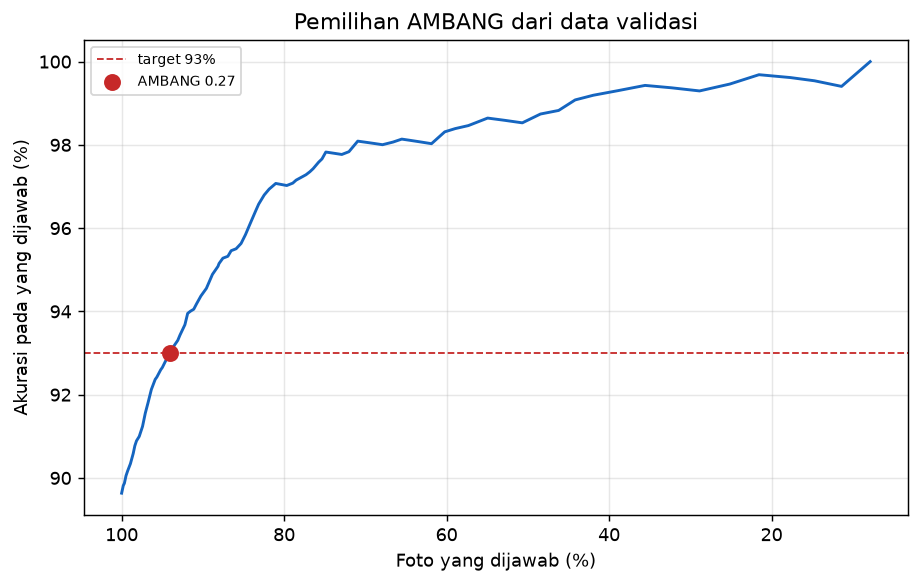

In [106]:
save_json(D / "safety_rules.json", rules)

# --- figur ---
fig, ax = plt.subplots(figsize=(7.2, 4.6))
d = df[df.akurasi.notna()]
ax.plot(d.cakupan * 100, d.akurasi * 100, color="#1565c0", lw=1.6)
ax.axhline(TARGET * 100, ls="--", color="#c62828", lw=1, label=f"target {TARGET:.0%}")
ax.scatter([chosen.cakupan * 100], [chosen.akurasi * 100], s=70, color="#c62828", zorder=5,
           label=f"AMBANG {AMBANG:.2f}")
ax.set_xlabel("Foto yang dijawab (%)"); ax.set_ylabel("Akurasi pada yang dijawab (%)")
ax.set_title("Pemilihan AMBANG dari data validasi")
ax.invert_xaxis(); ax.grid(alpha=.3); ax.legend(fontsize=8)
show_fig(fig, FIG / "ambang.png", dpi=130)

**Penjelasan output (grafik + log):** dua hal sekaligus. Baris `json -> ...` menyebut file `safety_rules.json` tersimpan. Grafiknya adalah kurva ambang: sumbu X nilai ambang keyakinan, sumbu Y akurasi pada foto yang dijawab dan cakupannya. Titik 0,27 ditandai karena di situlah syarat (akurasi ≥ 93%, cakupan ≥ 40%) mulai terpenuhi.

In [107]:
# --- tabel aturan ---
tampil("Aturan penolakan yang disimpan", pd.DataFrame({
    "Item": ["AMBANG", "Cakupan di validasi", "Akurasi di validasi", "Cakupan di test",
             "Akurasi di test", "Fatal di test"],
    "Nilai": [f"{AMBANG:.2f}", f"{chosen.cakupan:.1%}", f"{chosen.akurasi:.1%}",
              f"{sel.mean():.1%}", f"{acc_te:.1%}", f"{int(fatal_sel.sum())}/{n_tox_sel}"],
}))
print("DONE TAHAP 6a", flush=True)

**Aturan penolakan yang disimpan**

,Item,Nilai
0,AMBANG,0.27
1,Cakupan di validasi,94.0%
2,Akurasi di validasi,93.0%
3,Cakupan di test,93.4%
4,Akurasi di test,92.7%
5,Fatal di test,9/410


DONE TAHAP 6a


**Penjelasan output (log + tabel):** tabel aturan penolakan final yang disimpan. Nilai yang dipakai aplikasi adalah `AMBANG = 0.27`. Di validasi: cakupan 94,0%, akurasi 93,0%. Di test: cakupan 93,4%, akurasi 92,7%, fatal 9/410. Catatan penting: ambang dipilih dari validasi, sedangkan angka test hanya laporan — supaya hasil akhirnya tidak bias. `DONE TAHAP 6a` menandai tahap selesai.

---

# Tahap 6b · Biaya deploy SVM di HP

SVM menang tipis kalau semua foto dipaksa dijawab, tapi dia tidak bisa berdiri sendiri karena butuh embedding CNN.

**Tujuan:** menghitung apa yang harus dibayar kalau SVM benar-benar dibawa ke HP.

**Yang dilakukan:** menghitung jumlah support vector, ukuran bobot float32/float16, jumlah evaluasi kernel per inferensi, dan latensi referensi.

### 6b.1 Menghitung Biaya SVM

In [108]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, r"C:\Users\Wahyu Pratomo\Project Machine Learning\tanaman-obat\scripts")
from common import OUT, tampil, tampil_teks

SRC = OUT / "01_cnn"
D = OUT / "02_svm"

In [109]:
Xtr = np.load(SRC / "emb_train.npy")
ytr = np.load(SRC / "y_train.npy")
Xte = np.load(SRC / "emb_test.npy")
print(f"train {Xtr.shape}", flush=True)

train (6887, 1280)


**Penjelasan output (log):** `train (6887, 1280)` adalah bentuk embedding yang dipakai untuk menghitung ulang SVM versi deploy. Hanya train yang dimuat karena yang diukur adalah jumlah support vector dan ukuran bobot, bukan akurasi.

In [110]:
t0 = time.time()
pipe = make_pipeline(StandardScaler(),
                     SVC(C=10, gamma="scale", kernel="rbf",
                         decision_function_shape="ovr", cache_size=3000))
pipe.fit(Xtr, ytr)
print(f"refit {time.time()-t0:.1f} s", flush=True)

svm = pipe[-1]
scaler = pipe[0]
n_sv = int(svm.n_support_.sum())
n_features = Xtr.shape[1]
n_class = len(svm.classes_)

sv_float32_mb = n_sv * n_features * 4 / 1024 ** 2
sv_float16_mb = n_sv * n_features * 2 / 1024 ** 2
dual_coef_mb = svm.dual_coef_.size * 4 / 1024 ** 2

# biaya inferensi SVM di HP: kernel RBF = 1 dot product per support vector
kernels = n_sv                       # jumlah evaluasi kernel
flops = kernels * n_features * 2      # kali + tambah
per_class_scores = n_class

refit 48.3 s


**Penjelasan output (log):** `refit 48.3 s` adalah waktu melatih ulang SVM RBF (`C=10`) di luar pipeline standar. Refit dilakukan karena biaya deploy dihitung dari objek SVM mentah, sedangkan di Tahap 3 SVM dibungkus pipeline standardisasi + classifier.

In [111]:
t0 = time.time()
_ = pipe.decision_function(Xte[:200])
lat_py = (time.time() - t0) / 200

print(f"support vector {n_sv:,} | float32 {sv_float32_mb:.1f} MB | "
      f"float16 {sv_float16_mb:.1f} MB", flush=True)
print(f"kernel evals per inferensi {kernels:,} | ~{flops/1e6:.0f} MFLOP", flush=True)
print(f"latency referensi (desktop python) {lat_py*1000:.1f} ms/gambar", flush=True)

rec = "CNN-embedding + SVM RBF"

support vector 5,468 | float32 26.7 MB | float16 13.3 MB


kernel evals per inferensi 5,468 | ~14 MFLOP


latency referensi (desktop python) 8.6 ms/gambar


**Penjelasan output (log):** tiga fakta biaya SVM. `support vector 5,468` = banyak vektor pendukung, jadi setiap kali menebak aplikasi harus menghitung 5.468 kernel. `float32 26.7 MB | float16 13.3 MB` adalah ukuran bobot model — sudah lebih besar dari seluruh CNN (4,56 MB) walau dipadatkan. `latency referensi 8.6 ms/gambar` adalah patokan kasar di desktop Python, bukan di HP, dan setiap inferensi aplikasi jadi dua tahap (CNN lalu SVM).

In [112]:
def idn(v, d=1):
    return f"{v:.{d}f}".replace(".", ",")


# angka akurasi dibaca dari artefak, bukan ditulis tangan

In [113]:
def _read(p):
    return json.loads(Path(p).read_text(encoding="utf-8")) if Path(p).exists() else {}


m_svm = _read(D / "metrics.json")
m_cnn = _read(OUT / "01_cnn" / "metrics.json")

In [114]:
rules = _read(OUT / "05_bahan_aplikasi" / "safety_rules.json")
top1_svm = m_svm.get("top1")
top1_cnn = m_cnn.get("top1")
gain = (top1_svm - top1_cnn) * 100 if (top1_svm and top1_cnn) else None
kal_hasil = f"top-1 {idn(top1_svm*100)}%" if top1_svm else "akurasi tertinggi"

# akurasi pada cakupan yang sama, dari tabel perbandingan
acc_cov = {}
_tbl = OUT / "04_perbandingan" / "tabel_model.csv"
if _tbl.exists():
    import csv as _csv
    with _tbl.open(encoding="utf-8") as fh:
        for _row in _csv.DictReader(fh):
            _v = _row.get("akurasi_pada_cakupan")
            acc_cov[_row["model"]] = float(_v) if _v not in (None, "", "nan") else None
cnn_cov = acc_cov.get("CNN MobileNetV2")
svm_cov = acc_cov.get("SVM RBF")
cov = rules["test_pada_ambang_ini"]["cakupan"] if rules else None

if rules:
    _t = rules["test_pada_ambang_ini"]
    kal_tutup = (f"dengan `AMBANG = {idn(rules['ambang_keyakinan'], 2)}`, "
                 f"{idn(_t['cakupan'] * 100)}% foto dijawab dengan akurasi "
                 f"**{idn(_t['akurasi_pada_yang_dijawab']*100)}%**")
else:
    kal_tutup = "aturan penolakan"

if cnn_cov is not None and svm_cov is not None and cov:
    kal_banding = (f"Pada cakupan yang sama ({idn(cov * 100)}% foto dijawab), CNN "
                   f"malah **lebih akurat** daripada SVM: {idn(cnn_cov * 100)}% vs "
                   f"{idn(svm_cov * 100)}%. Jadi SVM tidak lagi punya alasan untuk "
                   f"dibawa ke HP.")
    kal_gain = (f"Kalau semua foto wajib dijawab, akurasi SVM naik {idn(gain)} poin "
                f"dibanding CNN murni — tapi keunggulan itu hilang begitu aturan "
                f"penolakan dipakai." if gain is not None else "")
else:
    kal_banding = "Perbandingan pada cakupan yang sama ditampilkan di tahap perbandingan notebook."
    kal_gain = f"Akurasi naik {idn(gain)} poin dibanding CNN murni." if gain is not None else ""

### 6b.2 Tabel Biaya Deploy

In [115]:
# --- tabel biaya deploy ---
tampil("Biaya membawa SVM ke HP", pd.DataFrame({
    "Item": ["Support vector", "Dimensi fitur", "Bobot SVM float32", "Bobot SVM float16",
             "Backbone CNN (tanpa kepala)", "Evaluasi kernel per inferensi",
             "Beban tambahan per inferensi", "Latensi referensi di laptop"],
    "Nilai": [f"{n_sv:,}", f"{n_features}", f"{idn(sv_float32_mb)} MB",
              f"{idn(sv_float16_mb)} MB", "~3,7 MB", f"{n_sv:,} x {n_features}",
              f"~{flops/1e6:.0f} MFLOP", f"{idn(lat_py*1000)} ms/gambar"],
}))
tampil_teks("**Kesimpulan:** yang dikirim ke HP adalah CNN murni. SVM butuh dua tahap dan sekitar "
            f"{idn(sv_float16_mb)} MB tambahan.")
print("DONE TAHAP 6b", flush=True)

**Biaya membawa SVM ke HP**

,Item,Nilai
0,Support vector,"5,468"
1,Dimensi fitur,1280
2,Bobot SVM float32,"26,7 MB"
3,Bobot SVM float16,"13,3 MB"
4,Backbone CNN (tanpa kepala),"~3,7 MB"
5,Evaluasi kernel per inferensi,"5,468 x 1280"
6,Beban tambahan per inferensi,~14 MFLOP
7,Latensi referensi di laptop,"8,6 ms/gambar"


**Kesimpulan:** yang dikirim ke HP adalah CNN murni. SVM butuh dua tahap dan sekitar 13,3 MB tambahan.

DONE TAHAP 6b


**Penjelasan output (log + tabel):** tabel rekap biaya membawa SVM ke HP. 5.468 support vector, fitur 1.280 dimensi, bobot 26,7 MB (float32) atau 13,3 MB (float16), ditambah backbone CNN ~3,7 MB, 5.468 × 1.280 evaluasi kernel (~14 MFLOP) per gambar, dan latensi referensi 8,6 ms. Kesimpulannya (tertulis di bawah tabel): yang dikirim ke HP cukup **CNN murni**, karena SVM butuh dua tahap dan belasan MB tambahan. `DONE TAHAP 6b` menandai seluruh pipeline selesai.